In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 200           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
NUM_CLASSES = 10
GENERATOR_FEATURE_MAPS = 128
DISCRIMINATOR_FEATURE_MAPS = 128

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 200
Generator feature maps: 128
Discriminator feature maps: 128
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    def __init__(self, noise_dim, feature_maps, num_classes):
        super().__init__()
        self.num_classes = num_classes
        input_channels = noise_dim + num_classes

        self.net = nn.Sequential(
            nn.Unflatten(1, (input_channels, 1, 1)),

            nn.ConvTranspose2d(input_channels, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise, labels):
        class_vectors = F.one_hot(labels, num_classes=self.num_classes).to(noise.dtype)
        return self.net(torch.cat((noise, class_vectors), dim=1))


In [6]:
class Discriminator(nn.Module):
    def __init__(self, feature_maps, num_classes):
        super().__init__()
        self.num_classes = num_classes

        self.net = nn.Sequential(
            nn.Conv2d(1 + num_classes, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, data, labels):
        class_maps = F.one_hot(labels, num_classes=self.num_classes).to(data.dtype)
        class_maps = class_maps[:, :, None, None].expand(-1, -1, data.size(2), data.size(3))
        return self.net(torch.cat((data, class_maps), dim=1))


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS, NUM_CLASSES)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS, NUM_CLASSES)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 853,249
Discriminator parameters: 549,761
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(26, 1, 1))
    (1): ConvTranspose2d(26, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(11, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.

In [8]:
def visualize_class_samples(classes, samples_per_class=5):
    class_labels = np.repeat(classes, samples_per_class)
    samples = generate_samples(len(class_labels), classes=class_labels)
    fig, axes = plt.subplots(
        len(classes), samples_per_class,
        figsize=(samples_per_class * 2, len(classes) * 2), squeeze=False,
    )

    for row, class_label in enumerate(classes):
        for column in range(samples_per_class):
            sample_index = row * samples_per_class + column
            axes[row, column].imshow(samples[sample_index].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
            axes[row, column].set_title(f'Class {class_label}')
            axes[row, column].axis('off')

    fig.tight_layout()
    plt.show()


In [9]:
def train_discriminator(real_data, class_labels):
    optimizer_D.zero_grad()
    real_data = real_data.to(device).float()
    class_labels = class_labels.to(device=device, dtype=torch.long)
    batch_size = real_data.size(0)

    real_output = discriminator(real_data, class_labels)
    real_targets = torch.ones_like(real_output)
    real_loss = criterion(real_output, real_targets)

    noise = torch.randn(batch_size, NOISE_DIM, device=device)
    with torch.no_grad():
        fake_data = generator(noise, class_labels)
    fake_output = discriminator(fake_data, class_labels)
    fake_targets = torch.zeros_like(fake_output)
    fake_loss = criterion(fake_output, fake_targets)

    d_loss = real_loss + fake_loss
    d_loss.backward()
    optimizer_D.step()
    return d_loss.item()


def evaluate_discriminator(real_data, class_labels):
    with torch.no_grad():
        real_data = real_data.to(device).float()
        class_labels = class_labels.to(device=device, dtype=torch.long)
        batch_size = real_data.size(0)

        real_output = discriminator(real_data, class_labels)
        real_targets = torch.ones_like(real_output)
        real_loss = criterion(real_output, real_targets)

        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_data = generator(noise, class_labels)
        fake_output = discriminator(fake_data, class_labels)
        fake_targets = torch.zeros_like(fake_output)
        fake_loss = criterion(fake_output, fake_targets)
        d_loss = real_loss + fake_loss

    return d_loss.item()


In [10]:
def train_generator(class_labels):
    optimizer_G.zero_grad()
    class_labels = class_labels.to(device=device, dtype=torch.long)
    batch_size = class_labels.size(0)

    noise = torch.randn(batch_size, NOISE_DIM, device=device)
    fake_data = generator(noise, class_labels)
    fake_output = discriminator(fake_data, class_labels)
    real_targets = torch.ones_like(fake_output)
    g_loss = criterion(fake_output, real_targets)

    g_loss.backward()
    optimizer_G.step()
    return g_loss.item()


def evaluate_generator(class_labels):
    with torch.no_grad():
        class_labels = class_labels.to(device=device, dtype=torch.long)
        batch_size = class_labels.size(0)

        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_data = generator(noise, class_labels)
        fake_output = discriminator(fake_data, class_labels)
        real_targets = torch.ones_like(fake_output)
        g_loss = criterion(fake_output, real_targets)

    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, labels)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(labels)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, labels)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(labels)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000, classes=None):
    if isinstance(num_samples, bool) or not isinstance(num_samples, (int, np.integer)) or num_samples <= 0:
        raise ValueError('num_samples must be a positive integer')

    if classes is None:
        class_labels = torch.randint(NUM_CLASSES, (num_samples,), device=device)
    else:
        class_labels = torch.as_tensor(classes, device=device)
        if class_labels.dtype == torch.bool or class_labels.is_floating_point() or class_labels.is_complex():
            raise ValueError('classes must contain integer class labels')
        if class_labels.ndim == 0:
            class_labels = class_labels.repeat(num_samples)
        if class_labels.ndim != 1 or class_labels.numel() != num_samples:
            raise ValueError('Provide one class or one class per generated sample')
        if torch.any((class_labels < 0) | (class_labels >= NUM_CLASSES)):
            raise ValueError(f'classes must be between 0 and {NUM_CLASSES - 1}')
        class_labels = class_labels.long()

    was_training = generator.training
    generator.eval()
    try:
        with torch.no_grad():
            samples = []
            for start in range(0, num_samples, BATCH_SIZE):
                batch_labels = class_labels[start:start + BATCH_SIZE]
                noise = torch.randn(len(batch_labels), NOISE_DIM, device=device)
                samples.append(generator(noise, batch_labels).flatten(1).cpu())
            return torch.cat(samples).numpy()
    finally:
        generator.train(was_training)


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline


In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_classes = np.arange(2000) % NUM_CLASSES
    generated_samples = generate_samples(2000, classes=generated_classes)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    visualize_class_samples(list(range(NUM_CLASSES)), samples_per_class=2)


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/200
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.412796	G_loss: 0.751867
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.373486	G_loss: 0.721073
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.362512	G_loss: 0.723447
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.385741	G_loss: 0.706942
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.370605	G_loss: 0.713198
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.379598	G_loss: 0.711612
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.383633	G_loss: 0.698962
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.383962	G_loss: 0.691599
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.382319	G_loss: 0.703499
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.386165	G_loss: 0.700559
====> Epoch: 1 Train D_loss: 1.3774, Train G_loss: 0.7142
====> Epoch: 1 Val D_loss: 1.3888, Val G_loss: 0.6685
📈 Epoch 1 Summary:
   Train D Loss: 1.3774, Val D Loss: 1.3888
   Train G Loss: 0.7142, Val G Loss: 0.6685

📊 Epoch 2/200
------------------------

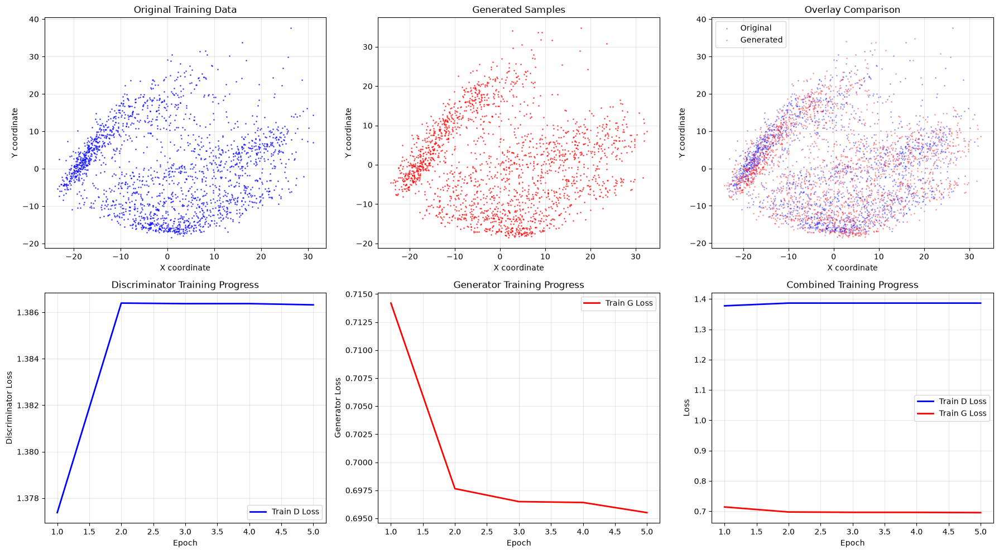

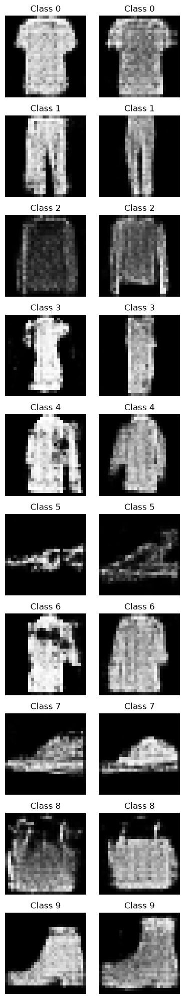

📈 Epoch 5 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3842
   Train G Loss: 0.6955, Val G Loss: 0.7031

📊 Epoch 6/200
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.383900	G_loss: 0.697611
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.382773	G_loss: 0.692900
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.388336	G_loss: 0.693435
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.385925	G_loss: 0.690300
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.386774	G_loss: 0.695092
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.384807	G_loss: 0.693427
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.386380	G_loss: 0.694144
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.387168	G_loss: 0.693693
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.383642	G_loss: 0.696980
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.387748	G_loss: 0.695042
====> Epoch: 6 Train D_loss: 1.3866, Train G_loss: 0.6953
====> Epoch: 6 Val D_loss: 1.3844, Val G_loss: 0.6877
📈 Epoch 6 Summary:
   Train D Loss: 1.3866, Val D Loss: 1.3844
   Train G Loss: 0.6953, Val G Loss: 0

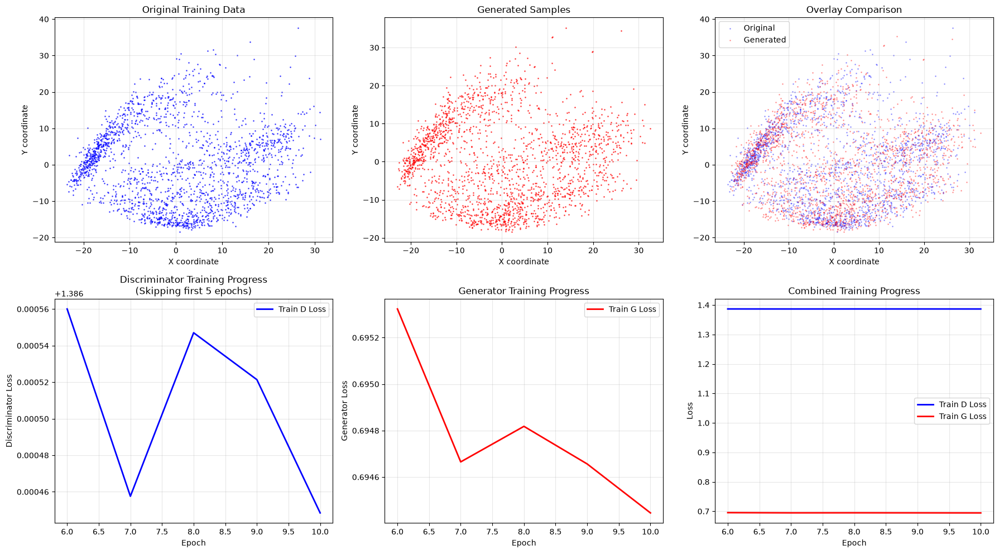

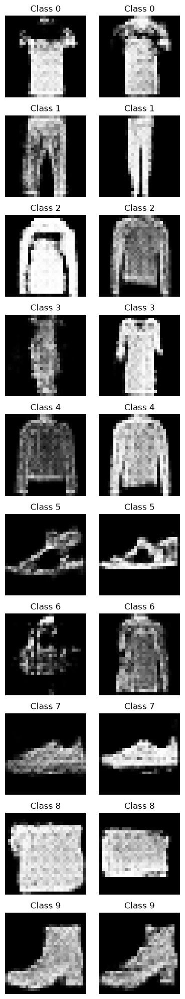

📈 Epoch 10 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3835
   Train G Loss: 0.6944, Val G Loss: 0.7022

📊 Epoch 11/200
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.384782	G_loss: 0.698029
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.386248	G_loss: 0.692115
Epoch: 11 [12800/60000 (21%)]	D_loss: 1.386957	G_loss: 0.696507
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.387249	G_loss: 0.698169
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.386992	G_loss: 0.692748
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.385419	G_loss: 0.700576
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.386566	G_loss: 0.704826
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.385075	G_loss: 0.697751
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.386097	G_loss: 0.691900
Epoch: 11 [57600/60000 (96%)]	D_loss: 1.385663	G_loss: 0.691326
====> Epoch: 11 Train D_loss: 1.3865, Train G_loss: 0.6947
====> Epoch: 11 Val D_loss: 1.3870, Val G_loss: 0.6751
📈 Epoch 11 Summary:
   Train D Loss: 1.3865, Val D Loss: 1.3870
   Train G Loss: 0.6947

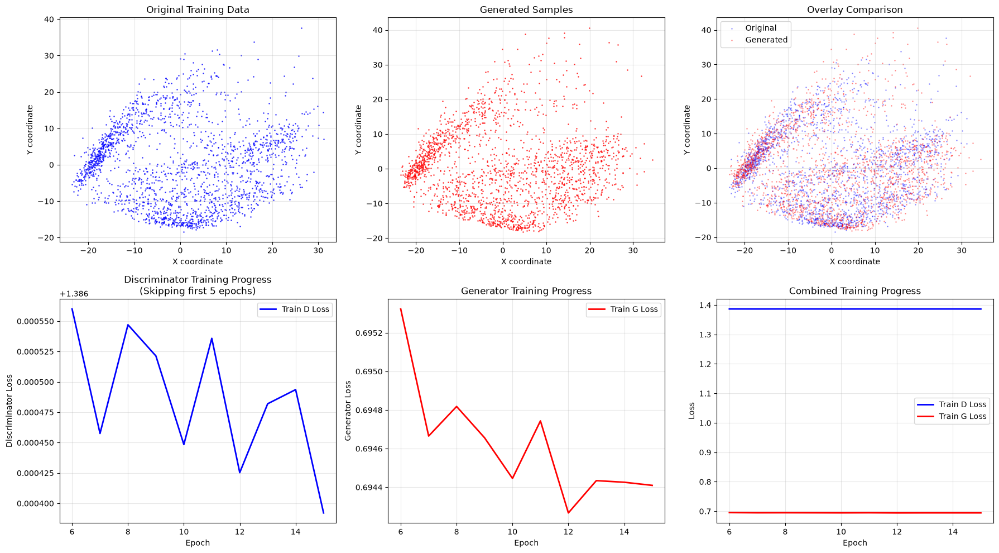

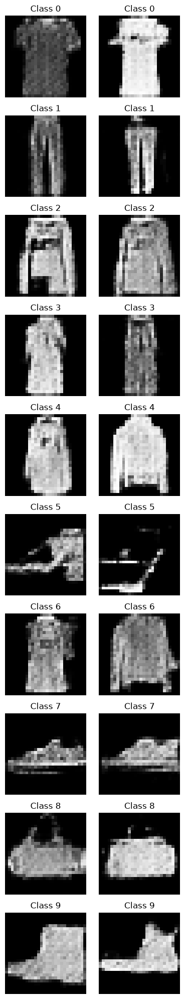

📈 Epoch 15 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3873
   Train G Loss: 0.6944, Val G Loss: 0.6996

📊 Epoch 16/200
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.384140	G_loss: 0.699591
Epoch: 16 [6400/60000 (11%)]	D_loss: 1.386258	G_loss: 0.694725
Epoch: 16 [12800/60000 (21%)]	D_loss: 1.385706	G_loss: 0.698959
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.385358	G_loss: 0.704009
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.387015	G_loss: 0.688447
Epoch: 16 [32000/60000 (53%)]	D_loss: 1.384211	G_loss: 0.694074
Epoch: 16 [38400/60000 (64%)]	D_loss: 1.387600	G_loss: 0.696044
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.386276	G_loss: 0.702680
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.386422	G_loss: 0.694482
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.387663	G_loss: 0.695808
====> Epoch: 16 Train D_loss: 1.3864, Train G_loss: 0.6944
====> Epoch: 16 Val D_loss: 1.3835, Val G_loss: 0.6977
📈 Epoch 16 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3835
   Train G Loss: 0.6944

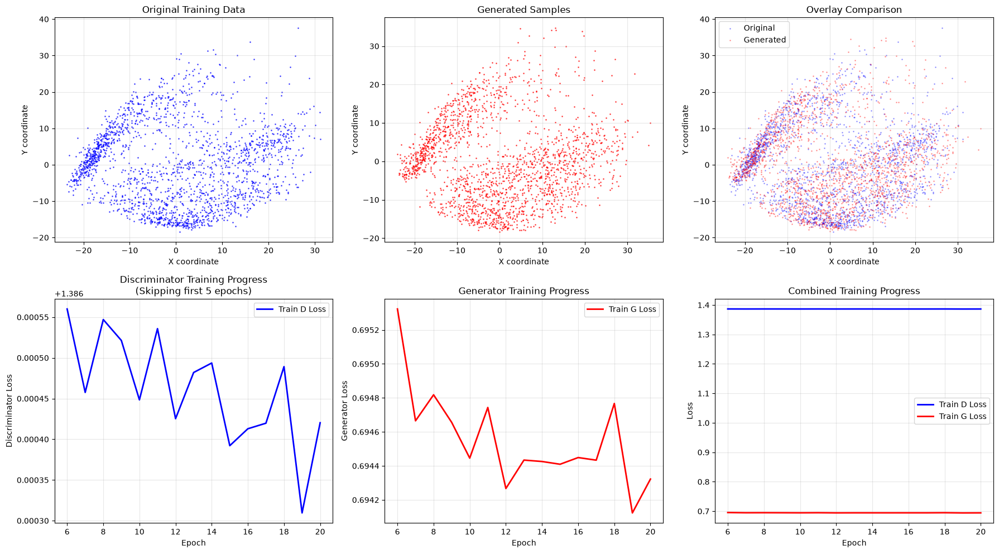

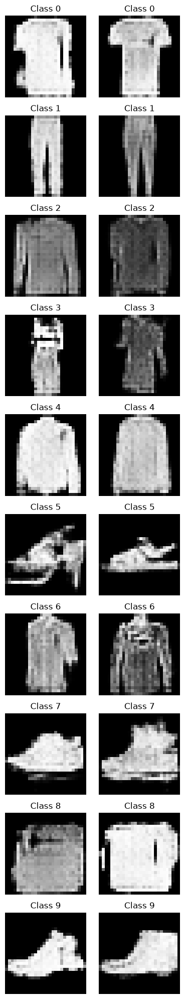

📈 Epoch 20 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3859
   Train G Loss: 0.6943, Val G Loss: 0.6906

📊 Epoch 21/200
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 1.385887	G_loss: 0.691403
Epoch: 21 [6400/60000 (11%)]	D_loss: 1.385991	G_loss: 0.694095
Epoch: 21 [12800/60000 (21%)]	D_loss: 1.386282	G_loss: 0.700713
Epoch: 21 [19200/60000 (32%)]	D_loss: 1.387187	G_loss: 0.700472
Epoch: 21 [25600/60000 (43%)]	D_loss: 1.386053	G_loss: 0.690572
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.385360	G_loss: 0.688408
Epoch: 21 [38400/60000 (64%)]	D_loss: 1.385536	G_loss: 0.691690
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.387098	G_loss: 0.696496
Epoch: 21 [51200/60000 (85%)]	D_loss: 1.385895	G_loss: 0.700469
Epoch: 21 [57600/60000 (96%)]	D_loss: 1.387362	G_loss: 0.699268
====> Epoch: 21 Train D_loss: 1.3864, Train G_loss: 0.6944
====> Epoch: 21 Val D_loss: 1.3847, Val G_loss: 0.6977
📈 Epoch 21 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3847
   Train G Loss: 0.6944

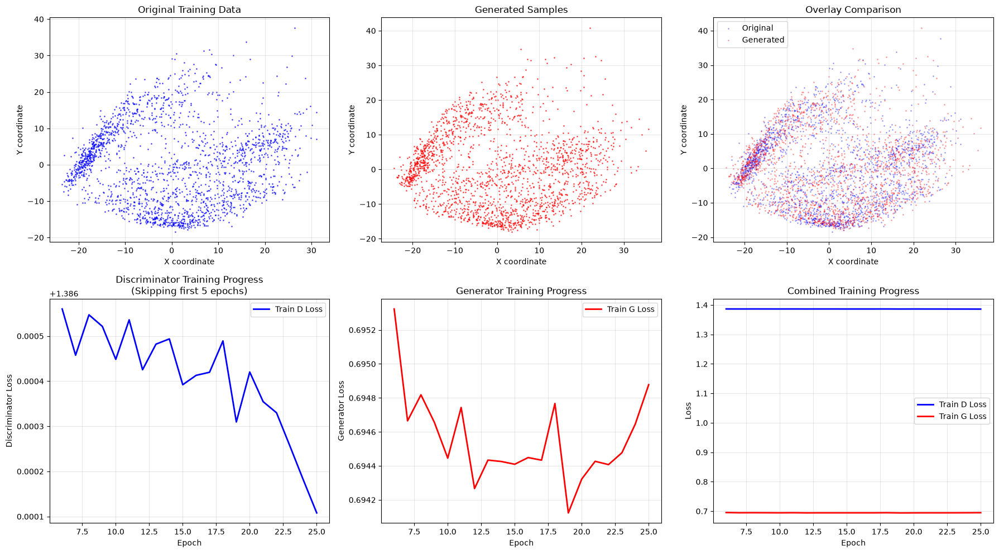

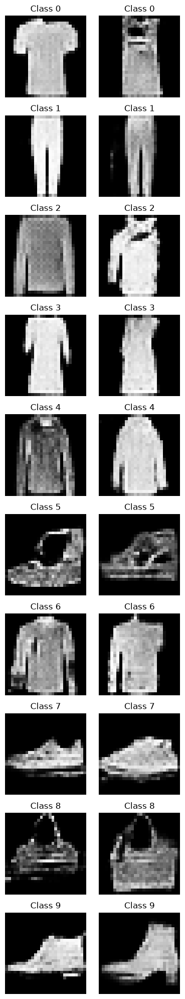

📈 Epoch 25 Summary:
   Train D Loss: 1.3861, Val D Loss: 1.3846
   Train G Loss: 0.6949, Val G Loss: 0.7010

📊 Epoch 26/200
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 1.384719	G_loss: 0.679430
Epoch: 26 [6400/60000 (11%)]	D_loss: 1.386075	G_loss: 0.694229
Epoch: 26 [12800/60000 (21%)]	D_loss: 1.385962	G_loss: 0.689994
Epoch: 26 [19200/60000 (32%)]	D_loss: 1.384714	G_loss: 0.690808
Epoch: 26 [25600/60000 (43%)]	D_loss: 1.384794	G_loss: 0.691969
Epoch: 26 [32000/60000 (53%)]	D_loss: 1.388171	G_loss: 0.703378
Epoch: 26 [38400/60000 (64%)]	D_loss: 1.384543	G_loss: 0.687602
Epoch: 26 [44800/60000 (75%)]	D_loss: 1.385934	G_loss: 0.697284
Epoch: 26 [51200/60000 (85%)]	D_loss: 1.385824	G_loss: 0.696537
Epoch: 26 [57600/60000 (96%)]	D_loss: 1.385824	G_loss: 0.699910
====> Epoch: 26 Train D_loss: 1.3859, Train G_loss: 0.6947
====> Epoch: 26 Val D_loss: 1.3847, Val G_loss: 0.6844
📈 Epoch 26 Summary:
   Train D Loss: 1.3859, Val D Loss: 1.3847
   Train G Loss: 0.6947

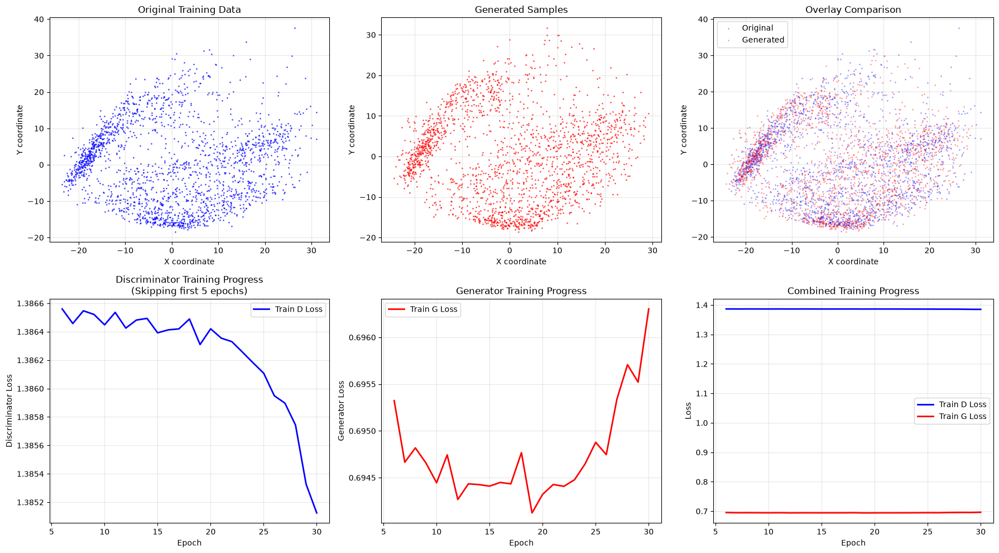

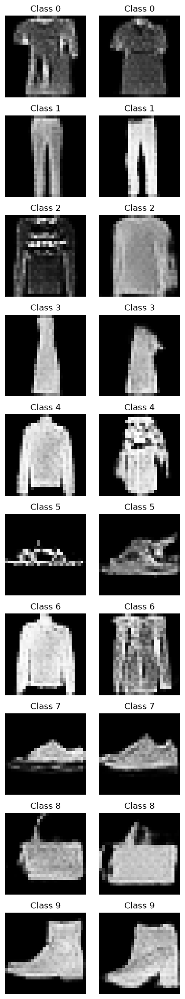

📈 Epoch 30 Summary:
   Train D Loss: 1.3851, Val D Loss: 1.3896
   Train G Loss: 0.6963, Val G Loss: 0.6898

📊 Epoch 31/200
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 1.387227	G_loss: 0.697085
Epoch: 31 [6400/60000 (11%)]	D_loss: 1.384051	G_loss: 0.699777
Epoch: 31 [12800/60000 (21%)]	D_loss: 1.384301	G_loss: 0.701810
Epoch: 31 [19200/60000 (32%)]	D_loss: 1.386713	G_loss: 0.698246
Epoch: 31 [25600/60000 (43%)]	D_loss: 1.381724	G_loss: 0.696346
Epoch: 31 [32000/60000 (53%)]	D_loss: 1.381416	G_loss: 0.694564
Epoch: 31 [38400/60000 (64%)]	D_loss: 1.383998	G_loss: 0.691602
Epoch: 31 [44800/60000 (75%)]	D_loss: 1.383758	G_loss: 0.692206
Epoch: 31 [51200/60000 (85%)]	D_loss: 1.386291	G_loss: 0.696189
Epoch: 31 [57600/60000 (96%)]	D_loss: 1.383792	G_loss: 0.698714
====> Epoch: 31 Train D_loss: 1.3847, Train G_loss: 0.6965
====> Epoch: 31 Val D_loss: 1.3862, Val G_loss: 0.7070
📈 Epoch 31 Summary:
   Train D Loss: 1.3847, Val D Loss: 1.3862
   Train G Loss: 0.6965

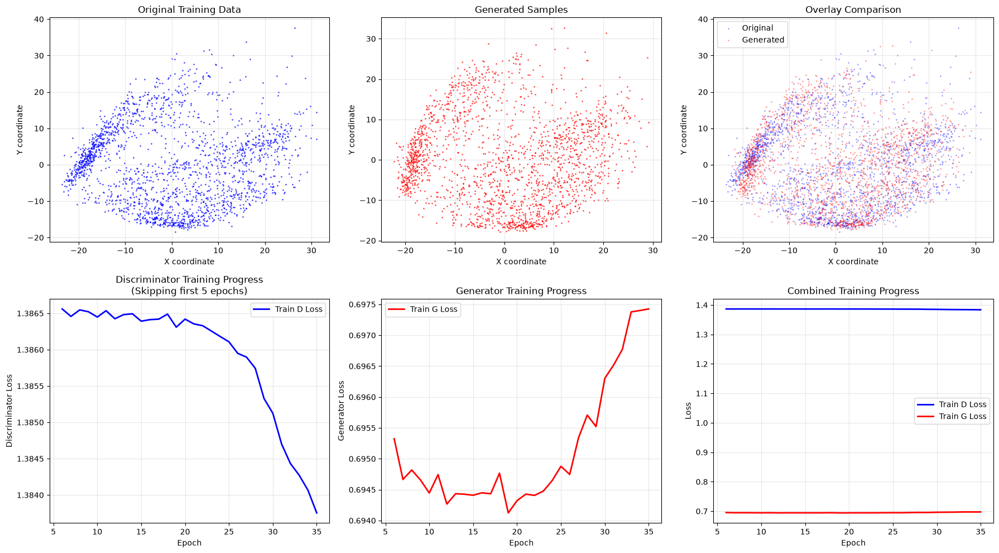

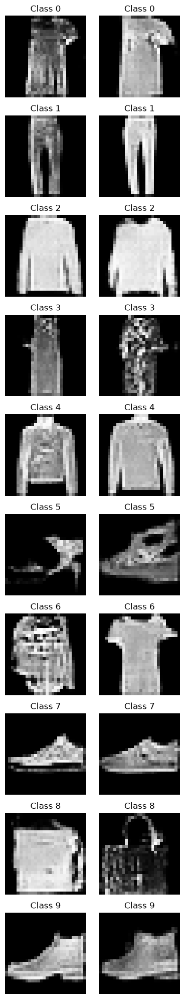

📈 Epoch 35 Summary:
   Train D Loss: 1.3838, Val D Loss: 1.3836
   Train G Loss: 0.6974, Val G Loss: 0.7203

📊 Epoch 36/200
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 1.382641	G_loss: 0.702778
Epoch: 36 [6400/60000 (11%)]	D_loss: 1.385295	G_loss: 0.696978
Epoch: 36 [12800/60000 (21%)]	D_loss: 1.382387	G_loss: 0.697845
Epoch: 36 [19200/60000 (32%)]	D_loss: 1.386239	G_loss: 0.697133
Epoch: 36 [25600/60000 (43%)]	D_loss: 1.381600	G_loss: 0.699697
Epoch: 36 [32000/60000 (53%)]	D_loss: 1.383404	G_loss: 0.697136
Epoch: 36 [38400/60000 (64%)]	D_loss: 1.387761	G_loss: 0.689002
Epoch: 36 [44800/60000 (75%)]	D_loss: 1.382023	G_loss: 0.703812
Epoch: 36 [51200/60000 (85%)]	D_loss: 1.381476	G_loss: 0.692521
Epoch: 36 [57600/60000 (96%)]	D_loss: 1.387343	G_loss: 0.695981
====> Epoch: 36 Train D_loss: 1.3838, Train G_loss: 0.6975
====> Epoch: 36 Val D_loss: 1.3836, Val G_loss: 0.7106
📈 Epoch 36 Summary:
   Train D Loss: 1.3838, Val D Loss: 1.3836
   Train G Loss: 0.6975

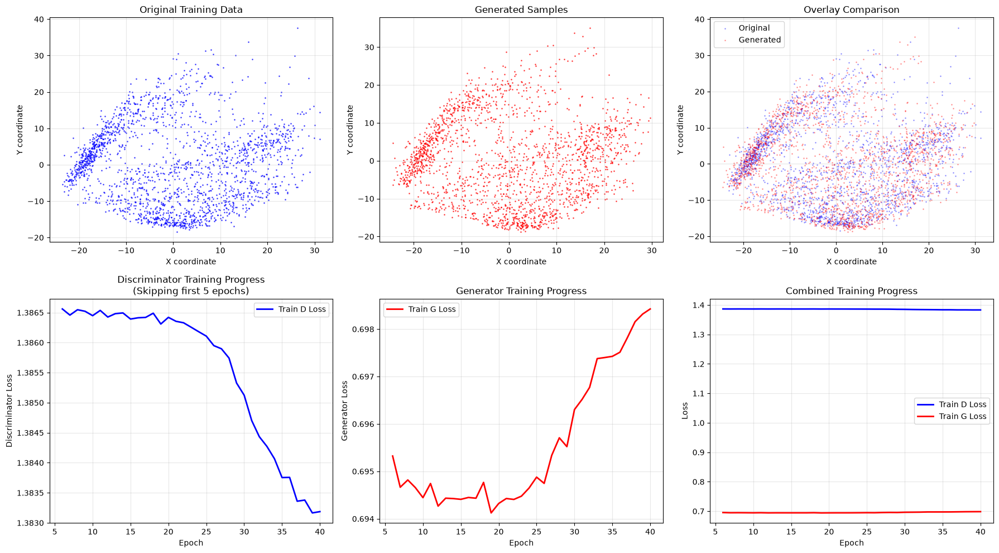

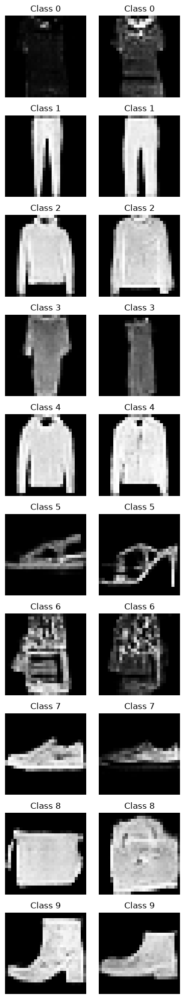

📈 Epoch 40 Summary:
   Train D Loss: 1.3832, Val D Loss: 1.3857
   Train G Loss: 0.6984, Val G Loss: 0.6536

📊 Epoch 41/200
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 1.381721	G_loss: 0.692102
Epoch: 41 [6400/60000 (11%)]	D_loss: 1.385546	G_loss: 0.696850
Epoch: 41 [12800/60000 (21%)]	D_loss: 1.378944	G_loss: 0.699997
Epoch: 41 [19200/60000 (32%)]	D_loss: 1.379427	G_loss: 0.696249
Epoch: 41 [25600/60000 (43%)]	D_loss: 1.381872	G_loss: 0.689967
Epoch: 41 [32000/60000 (53%)]	D_loss: 1.383730	G_loss: 0.687356
Epoch: 41 [38400/60000 (64%)]	D_loss: 1.381972	G_loss: 0.702021
Epoch: 41 [44800/60000 (75%)]	D_loss: 1.384578	G_loss: 0.696330
Epoch: 41 [51200/60000 (85%)]	D_loss: 1.380535	G_loss: 0.702180
Epoch: 41 [57600/60000 (96%)]	D_loss: 1.383003	G_loss: 0.702092
====> Epoch: 41 Train D_loss: 1.3828, Train G_loss: 0.6987
====> Epoch: 41 Val D_loss: 1.3835, Val G_loss: 0.6902
📈 Epoch 41 Summary:
   Train D Loss: 1.3828, Val D Loss: 1.3835
   Train G Loss: 0.6987

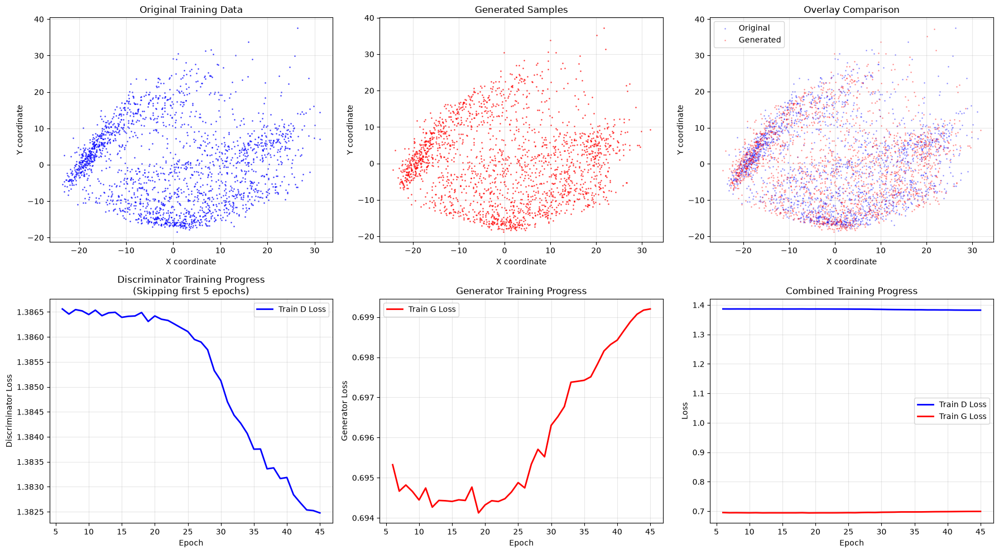

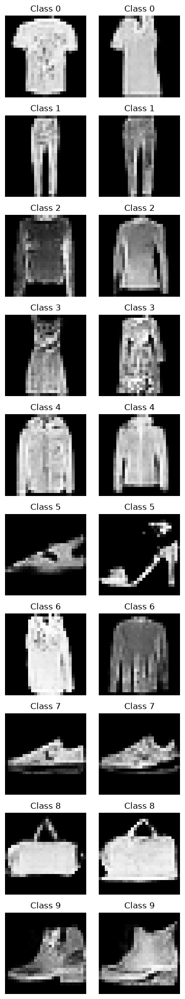

📈 Epoch 45 Summary:
   Train D Loss: 1.3825, Val D Loss: 1.3813
   Train G Loss: 0.6992, Val G Loss: 0.6763

📊 Epoch 46/200
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 1.380248	G_loss: 0.703790
Epoch: 46 [6400/60000 (11%)]	D_loss: 1.380175	G_loss: 0.705437
Epoch: 46 [12800/60000 (21%)]	D_loss: 1.381402	G_loss: 0.702839
Epoch: 46 [19200/60000 (32%)]	D_loss: 1.383768	G_loss: 0.699059
Epoch: 46 [25600/60000 (43%)]	D_loss: 1.383744	G_loss: 0.695571
Epoch: 46 [32000/60000 (53%)]	D_loss: 1.385947	G_loss: 0.707059
Epoch: 46 [38400/60000 (64%)]	D_loss: 1.383389	G_loss: 0.694558
Epoch: 46 [44800/60000 (75%)]	D_loss: 1.385932	G_loss: 0.698870
Epoch: 46 [51200/60000 (85%)]	D_loss: 1.383571	G_loss: 0.700214
Epoch: 46 [57600/60000 (96%)]	D_loss: 1.383301	G_loss: 0.700514
====> Epoch: 46 Train D_loss: 1.3824, Train G_loss: 0.6996
====> Epoch: 46 Val D_loss: 1.3815, Val G_loss: 0.7218
📈 Epoch 46 Summary:
   Train D Loss: 1.3824, Val D Loss: 1.3815
   Train G Loss: 0.6996

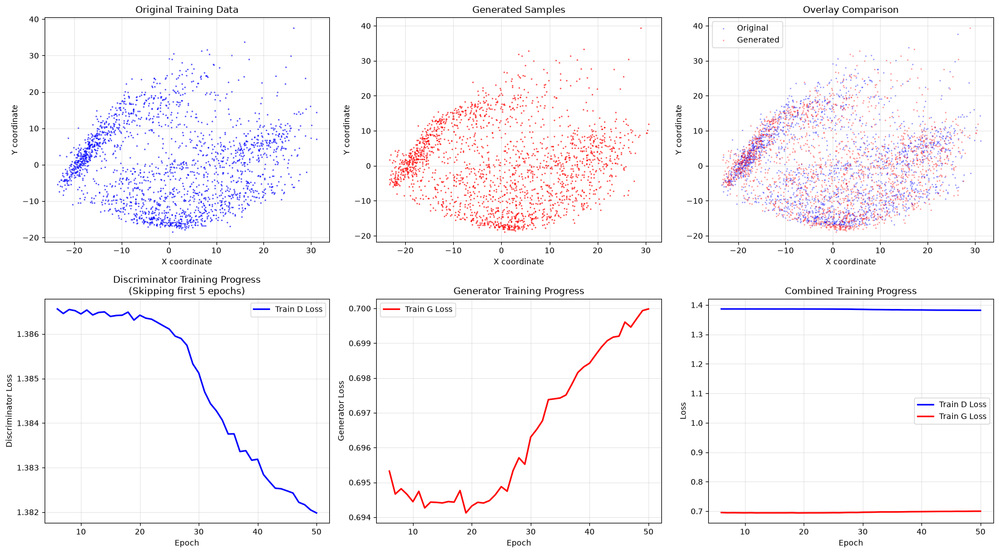

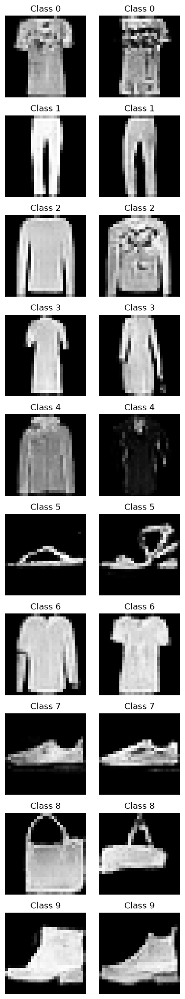

📈 Epoch 50 Summary:
   Train D Loss: 1.3820, Val D Loss: 1.3800
   Train G Loss: 0.7000, Val G Loss: 0.6965

📊 Epoch 51/200
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 1.377293	G_loss: 0.704957
Epoch: 51 [6400/60000 (11%)]	D_loss: 1.382709	G_loss: 0.688987
Epoch: 51 [12800/60000 (21%)]	D_loss: 1.381539	G_loss: 0.701796
Epoch: 51 [19200/60000 (32%)]	D_loss: 1.382867	G_loss: 0.698418
Epoch: 51 [25600/60000 (43%)]	D_loss: 1.379589	G_loss: 0.699159
Epoch: 51 [32000/60000 (53%)]	D_loss: 1.383335	G_loss: 0.686526
Epoch: 51 [38400/60000 (64%)]	D_loss: 1.379385	G_loss: 0.695348
Epoch: 51 [44800/60000 (75%)]	D_loss: 1.385328	G_loss: 0.695287
Epoch: 51 [51200/60000 (85%)]	D_loss: 1.390229	G_loss: 0.702160
Epoch: 51 [57600/60000 (96%)]	D_loss: 1.380814	G_loss: 0.704590
====> Epoch: 51 Train D_loss: 1.3819, Train G_loss: 0.7001
====> Epoch: 51 Val D_loss: 1.3843, Val G_loss: 0.7289
📈 Epoch 51 Summary:
   Train D Loss: 1.3819, Val D Loss: 1.3843
   Train G Loss: 0.7001

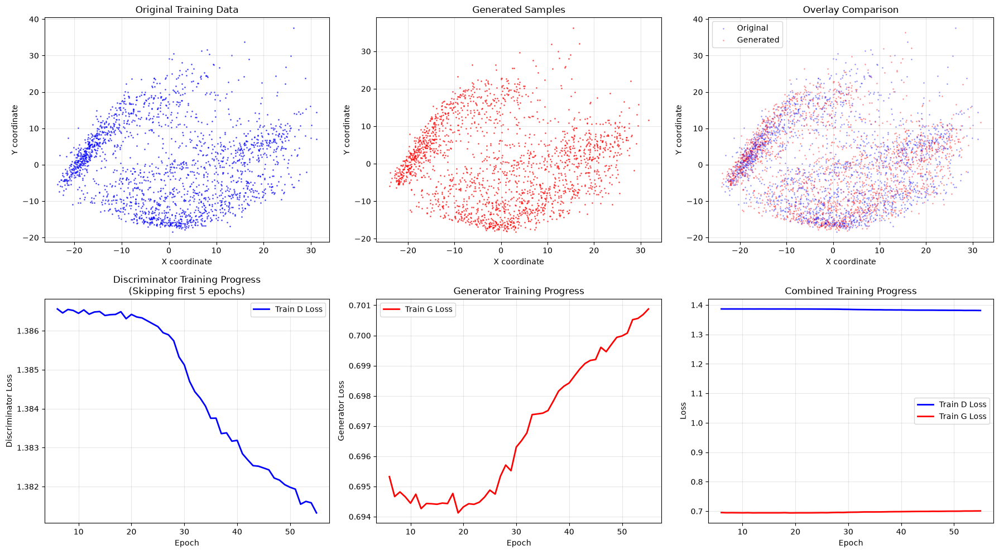

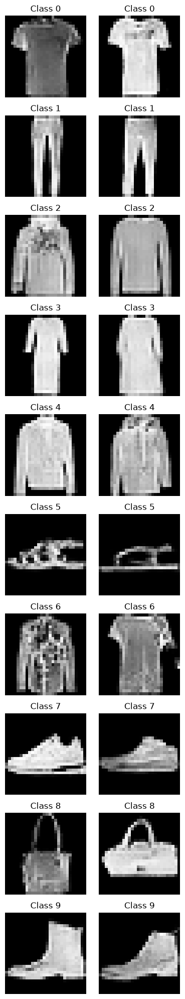

📈 Epoch 55 Summary:
   Train D Loss: 1.3813, Val D Loss: 1.3826
   Train G Loss: 0.7009, Val G Loss: 0.7093

📊 Epoch 56/200
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 1.385142	G_loss: 0.693368
Epoch: 56 [6400/60000 (11%)]	D_loss: 1.382817	G_loss: 0.703097
Epoch: 56 [12800/60000 (21%)]	D_loss: 1.380051	G_loss: 0.709795
Epoch: 56 [19200/60000 (32%)]	D_loss: 1.383644	G_loss: 0.701260
Epoch: 56 [25600/60000 (43%)]	D_loss: 1.380830	G_loss: 0.709858
Epoch: 56 [32000/60000 (53%)]	D_loss: 1.380973	G_loss: 0.703497
Epoch: 56 [38400/60000 (64%)]	D_loss: 1.380984	G_loss: 0.697203
Epoch: 56 [44800/60000 (75%)]	D_loss: 1.376946	G_loss: 0.694200
Epoch: 56 [51200/60000 (85%)]	D_loss: 1.382955	G_loss: 0.703586
Epoch: 56 [57600/60000 (96%)]	D_loss: 1.378820	G_loss: 0.700656
====> Epoch: 56 Train D_loss: 1.3811, Train G_loss: 0.7012
====> Epoch: 56 Val D_loss: 1.3820, Val G_loss: 0.7003
📈 Epoch 56 Summary:
   Train D Loss: 1.3811, Val D Loss: 1.3820
   Train G Loss: 0.7012

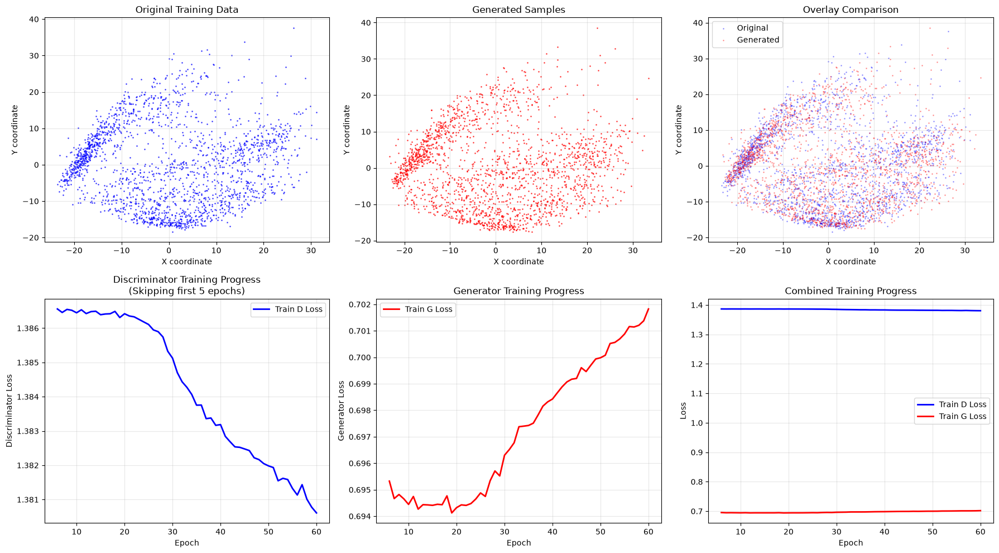

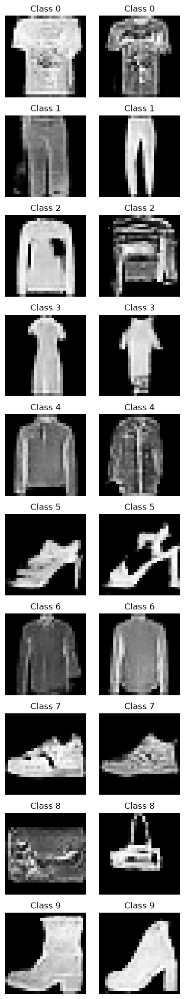

📈 Epoch 60 Summary:
   Train D Loss: 1.3806, Val D Loss: 1.3809
   Train G Loss: 0.7018, Val G Loss: 0.7062

📊 Epoch 61/200
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 1.385906	G_loss: 0.699791
Epoch: 61 [6400/60000 (11%)]	D_loss: 1.376661	G_loss: 0.704843
Epoch: 61 [12800/60000 (21%)]	D_loss: 1.376728	G_loss: 0.704627
Epoch: 61 [19200/60000 (32%)]	D_loss: 1.370784	G_loss: 0.699832
Epoch: 61 [25600/60000 (43%)]	D_loss: 1.377552	G_loss: 0.699467
Epoch: 61 [32000/60000 (53%)]	D_loss: 1.379759	G_loss: 0.706168
Epoch: 61 [38400/60000 (64%)]	D_loss: 1.382608	G_loss: 0.705132
Epoch: 61 [44800/60000 (75%)]	D_loss: 1.386685	G_loss: 0.704613
Epoch: 61 [51200/60000 (85%)]	D_loss: 1.374036	G_loss: 0.690725
Epoch: 61 [57600/60000 (96%)]	D_loss: 1.382717	G_loss: 0.706840
====> Epoch: 61 Train D_loss: 1.3806, Train G_loss: 0.7019
====> Epoch: 61 Val D_loss: 1.3814, Val G_loss: 0.7012
📈 Epoch 61 Summary:
   Train D Loss: 1.3806, Val D Loss: 1.3814
   Train G Loss: 0.7019

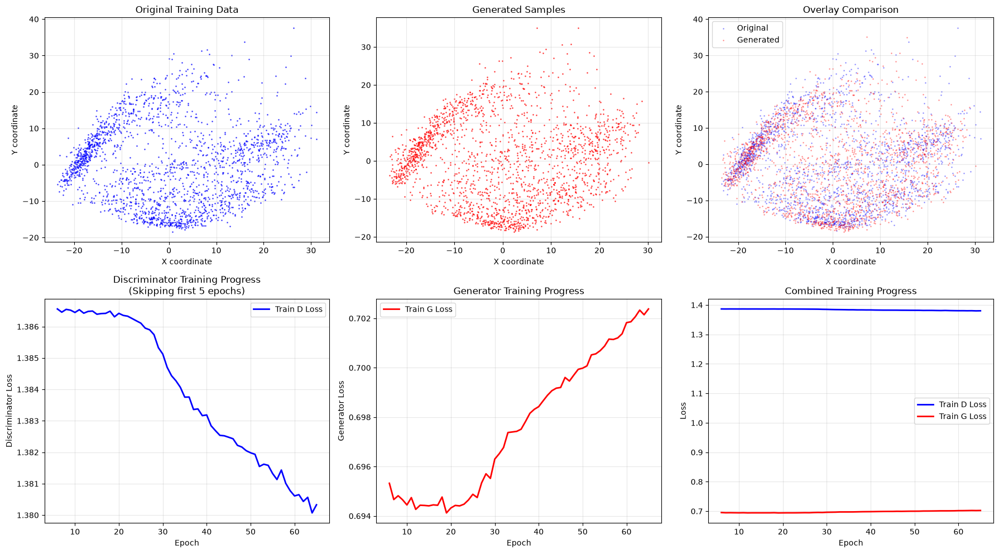

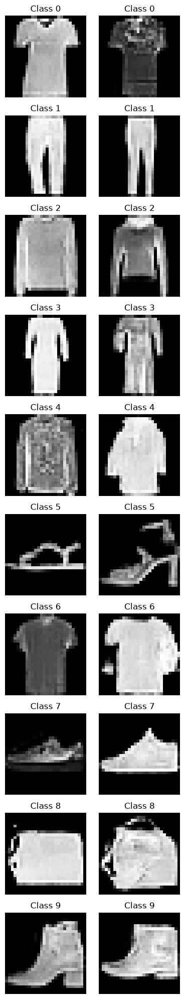

📈 Epoch 65 Summary:
   Train D Loss: 1.3803, Val D Loss: 1.3855
   Train G Loss: 0.7024, Val G Loss: 0.6522

📊 Epoch 66/200
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 1.386306	G_loss: 0.701537
Epoch: 66 [6400/60000 (11%)]	D_loss: 1.384353	G_loss: 0.704024
Epoch: 66 [12800/60000 (21%)]	D_loss: 1.382900	G_loss: 0.707653
Epoch: 66 [19200/60000 (32%)]	D_loss: 1.376616	G_loss: 0.707846
Epoch: 66 [25600/60000 (43%)]	D_loss: 1.381504	G_loss: 0.694969
Epoch: 66 [32000/60000 (53%)]	D_loss: 1.375106	G_loss: 0.704714
Epoch: 66 [38400/60000 (64%)]	D_loss: 1.387726	G_loss: 0.701361
Epoch: 66 [44800/60000 (75%)]	D_loss: 1.382004	G_loss: 0.697383
Epoch: 66 [51200/60000 (85%)]	D_loss: 1.380604	G_loss: 0.706071
Epoch: 66 [57600/60000 (96%)]	D_loss: 1.376843	G_loss: 0.699157
====> Epoch: 66 Train D_loss: 1.3799, Train G_loss: 0.7025
====> Epoch: 66 Val D_loss: 1.3789, Val G_loss: 0.7021
📈 Epoch 66 Summary:
   Train D Loss: 1.3799, Val D Loss: 1.3789
   Train G Loss: 0.7025

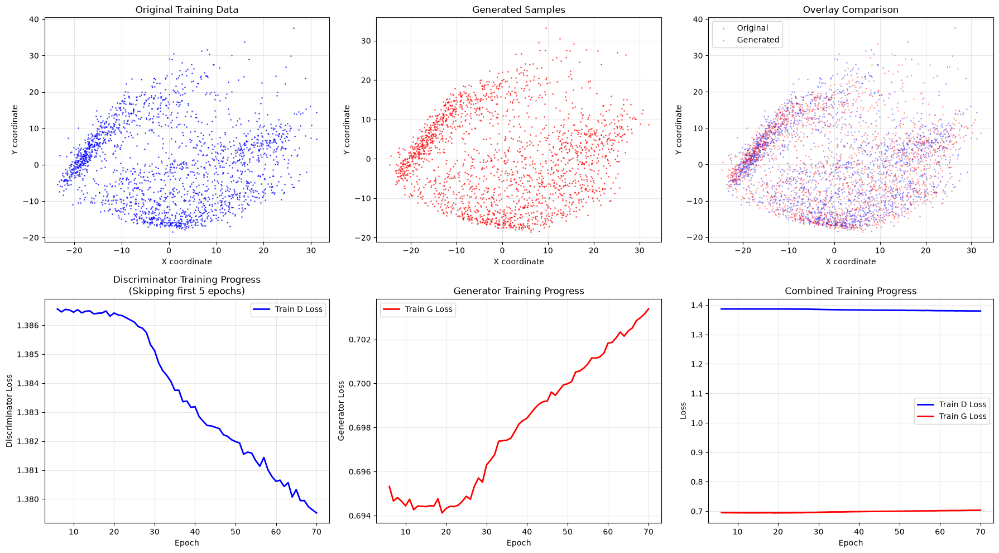

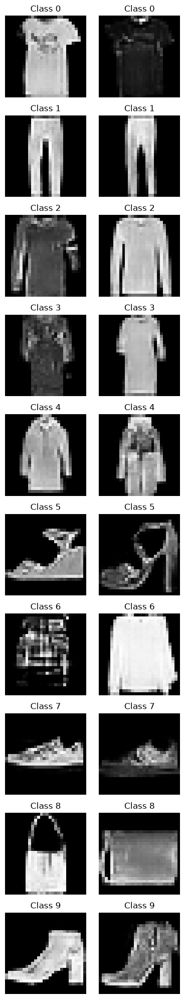

📈 Epoch 70 Summary:
   Train D Loss: 1.3795, Val D Loss: 1.3904
   Train G Loss: 0.7034, Val G Loss: 0.6702

📊 Epoch 71/200
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 1.391751	G_loss: 0.701440
Epoch: 71 [6400/60000 (11%)]	D_loss: 1.381032	G_loss: 0.716588
Epoch: 71 [12800/60000 (21%)]	D_loss: 1.380970	G_loss: 0.706806
Epoch: 71 [19200/60000 (32%)]	D_loss: 1.385728	G_loss: 0.695887
Epoch: 71 [25600/60000 (43%)]	D_loss: 1.375690	G_loss: 0.697880
Epoch: 71 [32000/60000 (53%)]	D_loss: 1.379813	G_loss: 0.705589
Epoch: 71 [38400/60000 (64%)]	D_loss: 1.385645	G_loss: 0.709432
Epoch: 71 [44800/60000 (75%)]	D_loss: 1.381541	G_loss: 0.710438
Epoch: 71 [51200/60000 (85%)]	D_loss: 1.372962	G_loss: 0.711456
Epoch: 71 [57600/60000 (96%)]	D_loss: 1.380234	G_loss: 0.697833
====> Epoch: 71 Train D_loss: 1.3791, Train G_loss: 0.7035
====> Epoch: 71 Val D_loss: 1.3832, Val G_loss: 0.7224
📈 Epoch 71 Summary:
   Train D Loss: 1.3791, Val D Loss: 1.3832
   Train G Loss: 0.7035

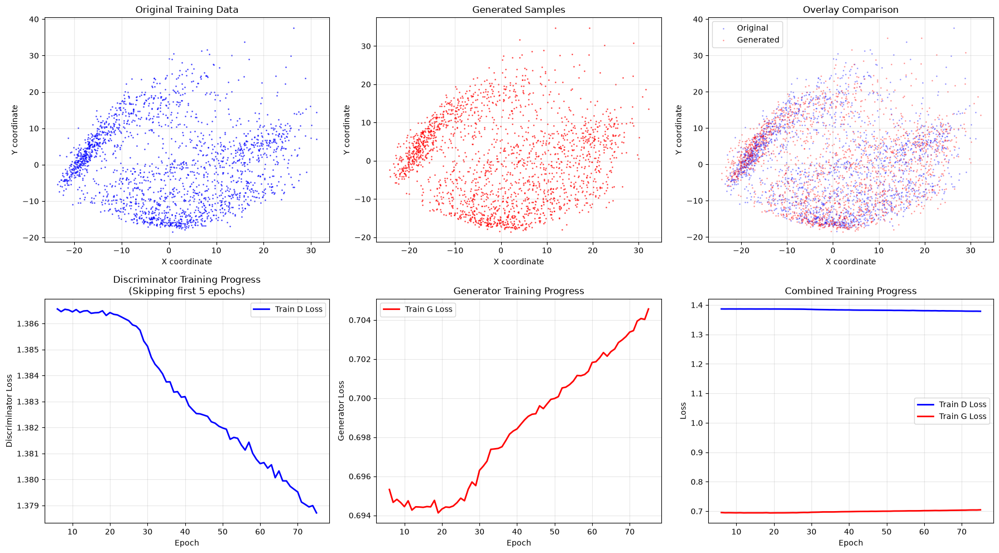

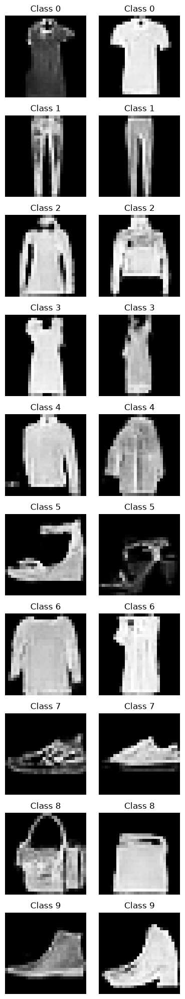

📈 Epoch 75 Summary:
   Train D Loss: 1.3787, Val D Loss: 1.3834
   Train G Loss: 0.7046, Val G Loss: 0.7439

📊 Epoch 76/200
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 1.375441	G_loss: 0.704016
Epoch: 76 [6400/60000 (11%)]	D_loss: 1.376230	G_loss: 0.710849
Epoch: 76 [12800/60000 (21%)]	D_loss: 1.379379	G_loss: 0.703356
Epoch: 76 [19200/60000 (32%)]	D_loss: 1.383240	G_loss: 0.711072
Epoch: 76 [25600/60000 (43%)]	D_loss: 1.380216	G_loss: 0.700284
Epoch: 76 [32000/60000 (53%)]	D_loss: 1.384805	G_loss: 0.700795
Epoch: 76 [38400/60000 (64%)]	D_loss: 1.375895	G_loss: 0.689319
Epoch: 76 [44800/60000 (75%)]	D_loss: 1.378314	G_loss: 0.703409
Epoch: 76 [51200/60000 (85%)]	D_loss: 1.381498	G_loss: 0.706514
Epoch: 76 [57600/60000 (96%)]	D_loss: 1.378186	G_loss: 0.707031
====> Epoch: 76 Train D_loss: 1.3784, Train G_loss: 0.7044
====> Epoch: 76 Val D_loss: 1.3806, Val G_loss: 0.6901
📈 Epoch 76 Summary:
   Train D Loss: 1.3784, Val D Loss: 1.3806
   Train G Loss: 0.7044

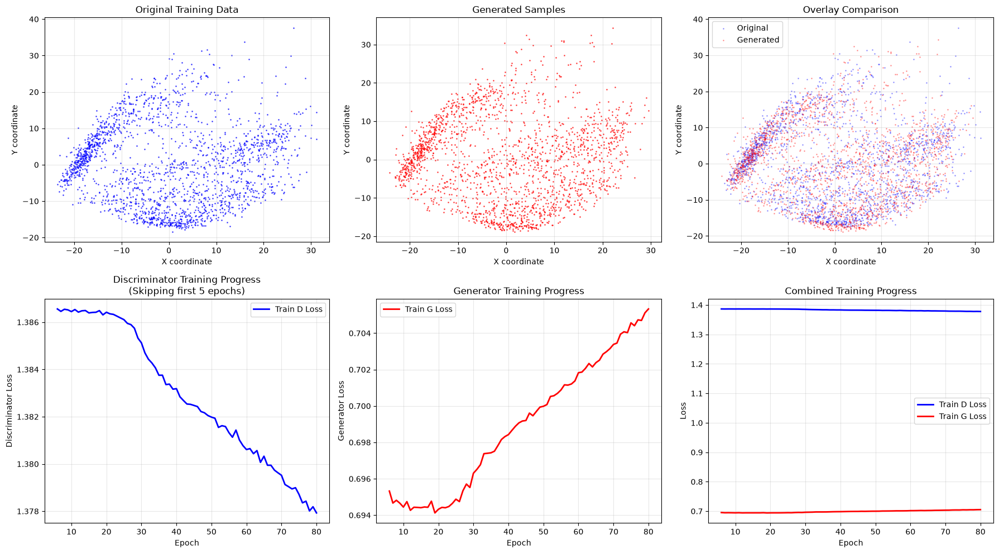

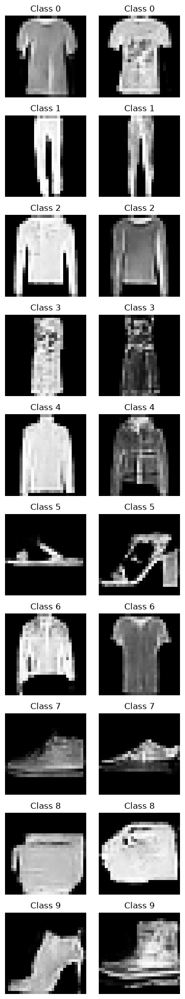

📈 Epoch 80 Summary:
   Train D Loss: 1.3779, Val D Loss: 1.3840
   Train G Loss: 0.7053, Val G Loss: 0.6455

📊 Epoch 81/200
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 1.376921	G_loss: 0.705183
Epoch: 81 [6400/60000 (11%)]	D_loss: 1.379972	G_loss: 0.710171
Epoch: 81 [12800/60000 (21%)]	D_loss: 1.379194	G_loss: 0.705435
Epoch: 81 [19200/60000 (32%)]	D_loss: 1.377850	G_loss: 0.707432
Epoch: 81 [25600/60000 (43%)]	D_loss: 1.375113	G_loss: 0.721552
Epoch: 81 [32000/60000 (53%)]	D_loss: 1.382807	G_loss: 0.713181
Epoch: 81 [38400/60000 (64%)]	D_loss: 1.386796	G_loss: 0.693271
Epoch: 81 [44800/60000 (75%)]	D_loss: 1.384101	G_loss: 0.704807
Epoch: 81 [51200/60000 (85%)]	D_loss: 1.376493	G_loss: 0.703218
Epoch: 81 [57600/60000 (96%)]	D_loss: 1.379105	G_loss: 0.715393
====> Epoch: 81 Train D_loss: 1.3778, Train G_loss: 0.7055
====> Epoch: 81 Val D_loss: 1.3774, Val G_loss: 0.7034
📈 Epoch 81 Summary:
   Train D Loss: 1.3778, Val D Loss: 1.3774
   Train G Loss: 0.7055

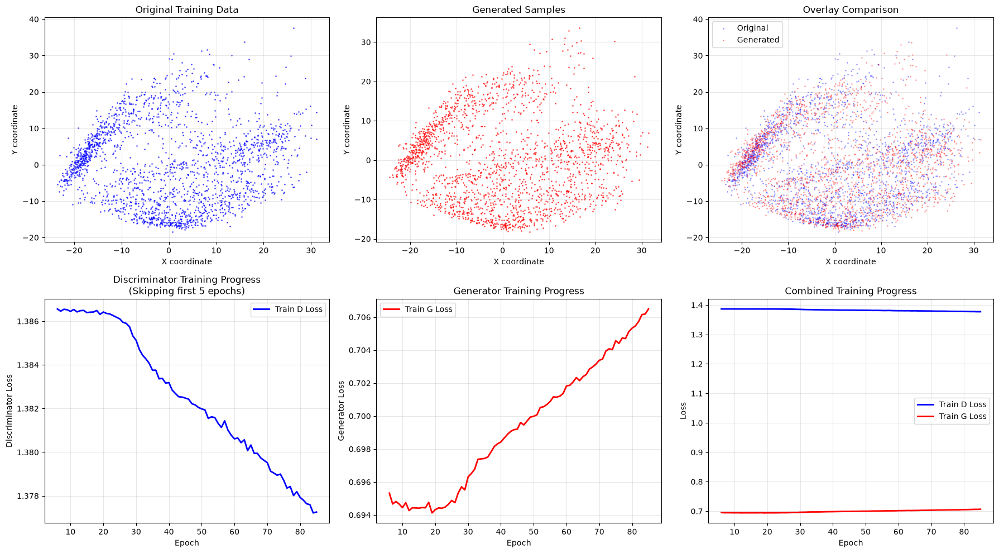

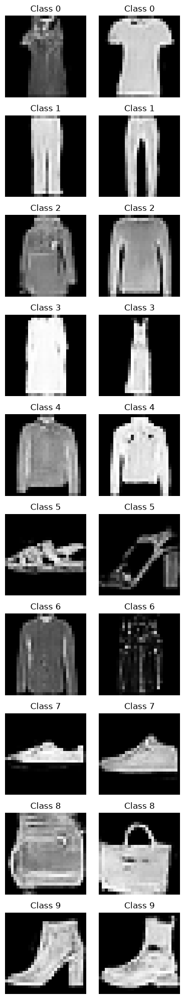

📈 Epoch 85 Summary:
   Train D Loss: 1.3773, Val D Loss: 1.3771
   Train G Loss: 0.7065, Val G Loss: 0.6919

📊 Epoch 86/200
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 1.374740	G_loss: 0.708236
Epoch: 86 [6400/60000 (11%)]	D_loss: 1.377676	G_loss: 0.715659
Epoch: 86 [12800/60000 (21%)]	D_loss: 1.379327	G_loss: 0.709467
Epoch: 86 [19200/60000 (32%)]	D_loss: 1.372351	G_loss: 0.708947
Epoch: 86 [25600/60000 (43%)]	D_loss: 1.381518	G_loss: 0.708842
Epoch: 86 [32000/60000 (53%)]	D_loss: 1.379403	G_loss: 0.714044
Epoch: 86 [38400/60000 (64%)]	D_loss: 1.379810	G_loss: 0.712006
Epoch: 86 [44800/60000 (75%)]	D_loss: 1.376595	G_loss: 0.712122
Epoch: 86 [51200/60000 (85%)]	D_loss: 1.372699	G_loss: 0.714523
Epoch: 86 [57600/60000 (96%)]	D_loss: 1.372794	G_loss: 0.694530
====> Epoch: 86 Train D_loss: 1.3767, Train G_loss: 0.7064
====> Epoch: 86 Val D_loss: 1.3813, Val G_loss: 0.6960
📈 Epoch 86 Summary:
   Train D Loss: 1.3767, Val D Loss: 1.3813
   Train G Loss: 0.7064

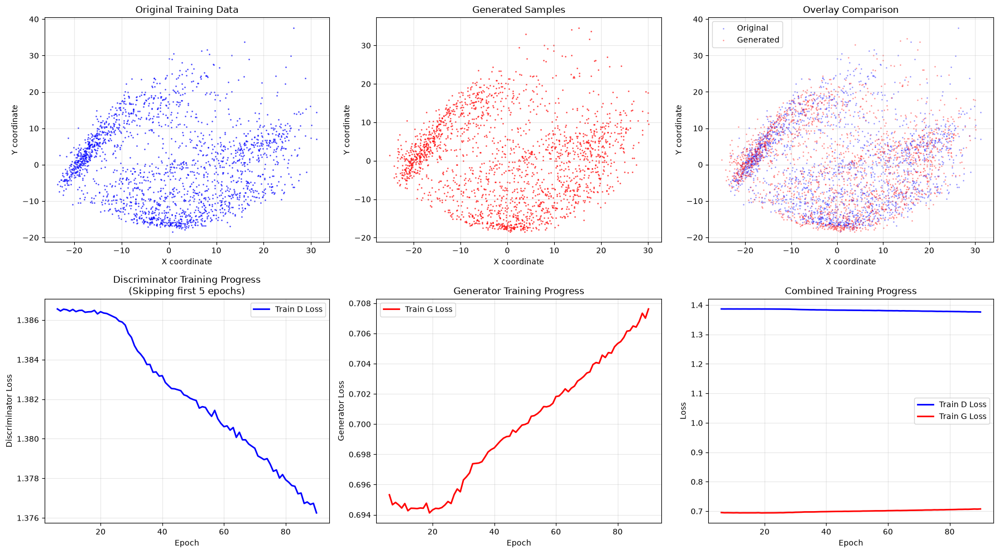

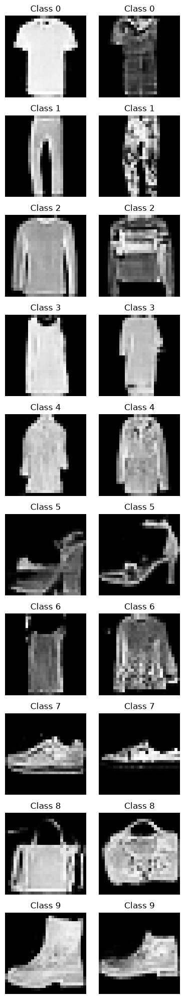

📈 Epoch 90 Summary:
   Train D Loss: 1.3763, Val D Loss: 1.3799
   Train G Loss: 0.7076, Val G Loss: 0.6818

📊 Epoch 91/200
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 1.375434	G_loss: 0.693720
Epoch: 91 [6400/60000 (11%)]	D_loss: 1.369164	G_loss: 0.710279
Epoch: 91 [12800/60000 (21%)]	D_loss: 1.378401	G_loss: 0.714318
Epoch: 91 [19200/60000 (32%)]	D_loss: 1.378505	G_loss: 0.714980
Epoch: 91 [25600/60000 (43%)]	D_loss: 1.376579	G_loss: 0.698560
Epoch: 91 [32000/60000 (53%)]	D_loss: 1.377267	G_loss: 0.715398
Epoch: 91 [38400/60000 (64%)]	D_loss: 1.377163	G_loss: 0.712202
Epoch: 91 [44800/60000 (75%)]	D_loss: 1.383039	G_loss: 0.707771
Epoch: 91 [51200/60000 (85%)]	D_loss: 1.373702	G_loss: 0.716105
Epoch: 91 [57600/60000 (96%)]	D_loss: 1.371666	G_loss: 0.710442
====> Epoch: 91 Train D_loss: 1.3764, Train G_loss: 0.7078
====> Epoch: 91 Val D_loss: 1.3799, Val G_loss: 0.7053
📈 Epoch 91 Summary:
   Train D Loss: 1.3764, Val D Loss: 1.3799
   Train G Loss: 0.7078

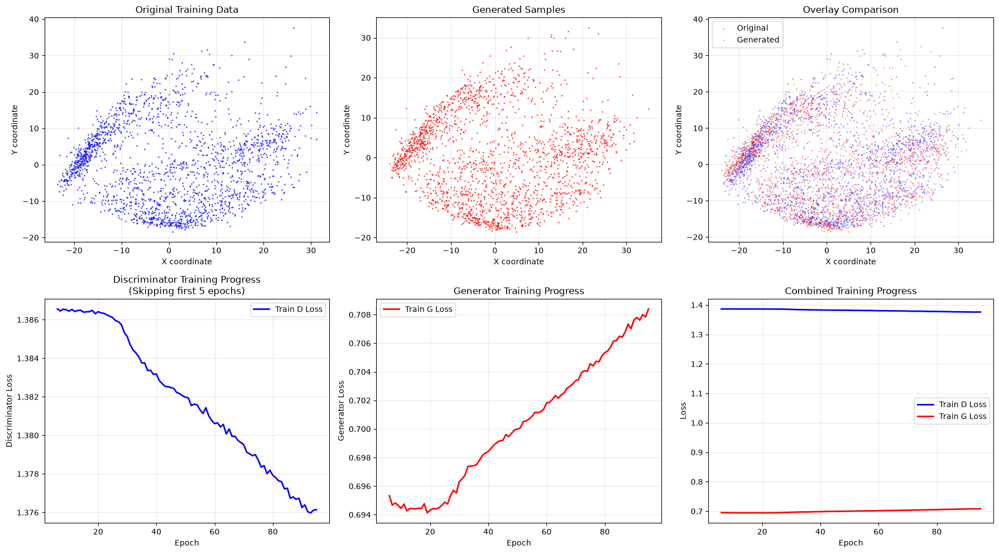

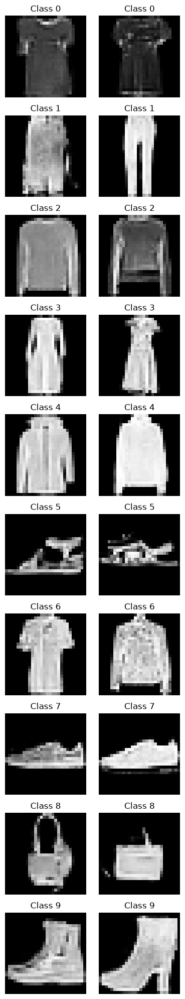

📈 Epoch 95 Summary:
   Train D Loss: 1.3761, Val D Loss: 1.3819
   Train G Loss: 0.7084, Val G Loss: 0.6743

📊 Epoch 96/200
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 1.376416	G_loss: 0.708076
Epoch: 96 [6400/60000 (11%)]	D_loss: 1.373143	G_loss: 0.709002
Epoch: 96 [12800/60000 (21%)]	D_loss: 1.376097	G_loss: 0.710287
Epoch: 96 [19200/60000 (32%)]	D_loss: 1.378184	G_loss: 0.717143
Epoch: 96 [25600/60000 (43%)]	D_loss: 1.376737	G_loss: 0.711475
Epoch: 96 [32000/60000 (53%)]	D_loss: 1.379375	G_loss: 0.698008
Epoch: 96 [38400/60000 (64%)]	D_loss: 1.373649	G_loss: 0.712744
Epoch: 96 [44800/60000 (75%)]	D_loss: 1.391789	G_loss: 0.722368
Epoch: 96 [51200/60000 (85%)]	D_loss: 1.380538	G_loss: 0.701483
Epoch: 96 [57600/60000 (96%)]	D_loss: 1.381625	G_loss: 0.701259
====> Epoch: 96 Train D_loss: 1.3758, Train G_loss: 0.7082
====> Epoch: 96 Val D_loss: 1.3789, Val G_loss: 0.7226
📈 Epoch 96 Summary:
   Train D Loss: 1.3758, Val D Loss: 1.3789
   Train G Loss: 0.7082

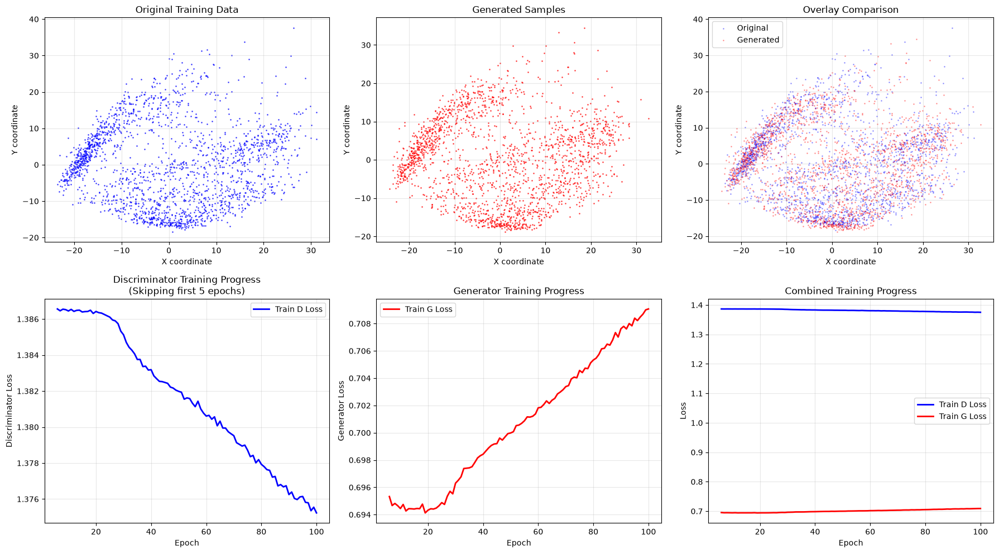

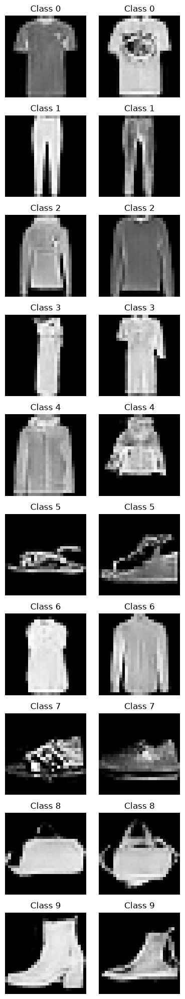

📈 Epoch 100 Summary:
   Train D Loss: 1.3752, Val D Loss: 1.3831
   Train G Loss: 0.7091, Val G Loss: 0.7068

📊 Epoch 101/200
----------------------------------------
Epoch: 101 [0/60000 (0%)]	D_loss: 1.373777	G_loss: 0.709168
Epoch: 101 [6400/60000 (11%)]	D_loss: 1.377058	G_loss: 0.707283
Epoch: 101 [12800/60000 (21%)]	D_loss: 1.363632	G_loss: 0.706978
Epoch: 101 [19200/60000 (32%)]	D_loss: 1.375245	G_loss: 0.705643
Epoch: 101 [25600/60000 (43%)]	D_loss: 1.381947	G_loss: 0.717744
Epoch: 101 [32000/60000 (53%)]	D_loss: 1.384968	G_loss: 0.714296
Epoch: 101 [38400/60000 (64%)]	D_loss: 1.371874	G_loss: 0.715605
Epoch: 101 [44800/60000 (75%)]	D_loss: 1.371606	G_loss: 0.709567
Epoch: 101 [51200/60000 (85%)]	D_loss: 1.374200	G_loss: 0.701550
Epoch: 101 [57600/60000 (96%)]	D_loss: 1.379430	G_loss: 0.702588
====> Epoch: 101 Train D_loss: 1.3751, Train G_loss: 0.7094
====> Epoch: 101 Val D_loss: 1.3791, Val G_loss: 0.7458
📈 Epoch 101 Summary:
   Train D Loss: 1.3751, Val D Loss: 1.3791
   Train

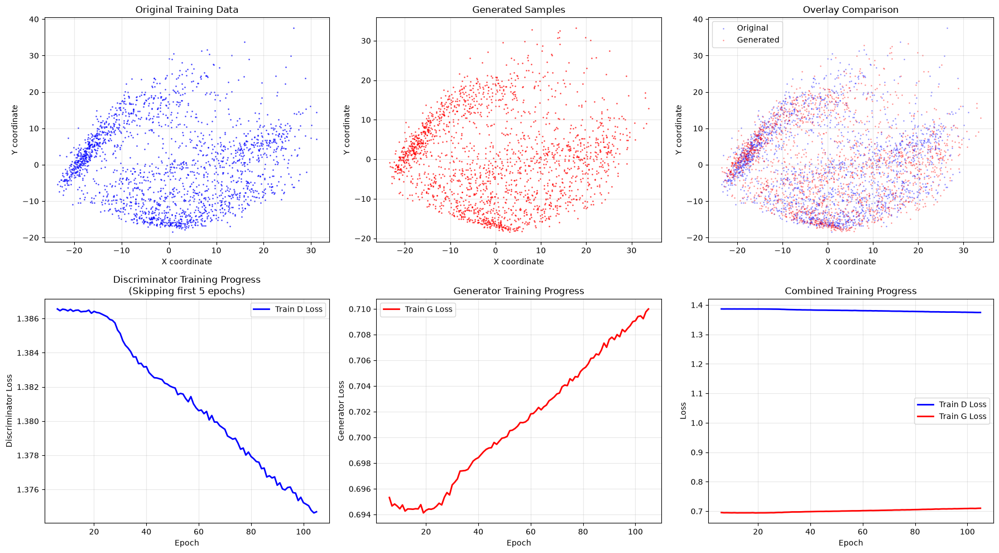

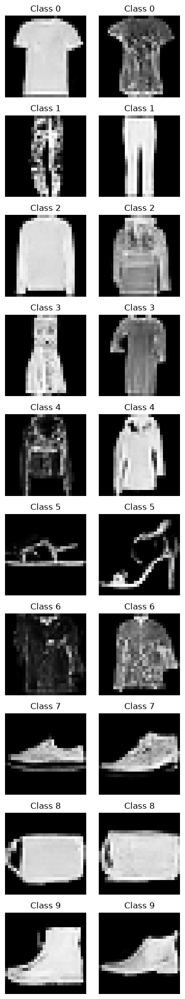

📈 Epoch 105 Summary:
   Train D Loss: 1.3747, Val D Loss: 1.3824
   Train G Loss: 0.7100, Val G Loss: 0.7523

📊 Epoch 106/200
----------------------------------------
Epoch: 106 [0/60000 (0%)]	D_loss: 1.373848	G_loss: 0.707859
Epoch: 106 [6400/60000 (11%)]	D_loss: 1.377066	G_loss: 0.709871
Epoch: 106 [12800/60000 (21%)]	D_loss: 1.375757	G_loss: 0.706805
Epoch: 106 [19200/60000 (32%)]	D_loss: 1.373223	G_loss: 0.700453
Epoch: 106 [25600/60000 (43%)]	D_loss: 1.382895	G_loss: 0.708051
Epoch: 106 [32000/60000 (53%)]	D_loss: 1.379562	G_loss: 0.705326
Epoch: 106 [38400/60000 (64%)]	D_loss: 1.381862	G_loss: 0.711177
Epoch: 106 [44800/60000 (75%)]	D_loss: 1.376989	G_loss: 0.714935
Epoch: 106 [51200/60000 (85%)]	D_loss: 1.375847	G_loss: 0.724613
Epoch: 106 [57600/60000 (96%)]	D_loss: 1.378233	G_loss: 0.720227
====> Epoch: 106 Train D_loss: 1.3746, Train G_loss: 0.7100
====> Epoch: 106 Val D_loss: 1.3765, Val G_loss: 0.7368
📈 Epoch 106 Summary:
   Train D Loss: 1.3746, Val D Loss: 1.3765
   Train

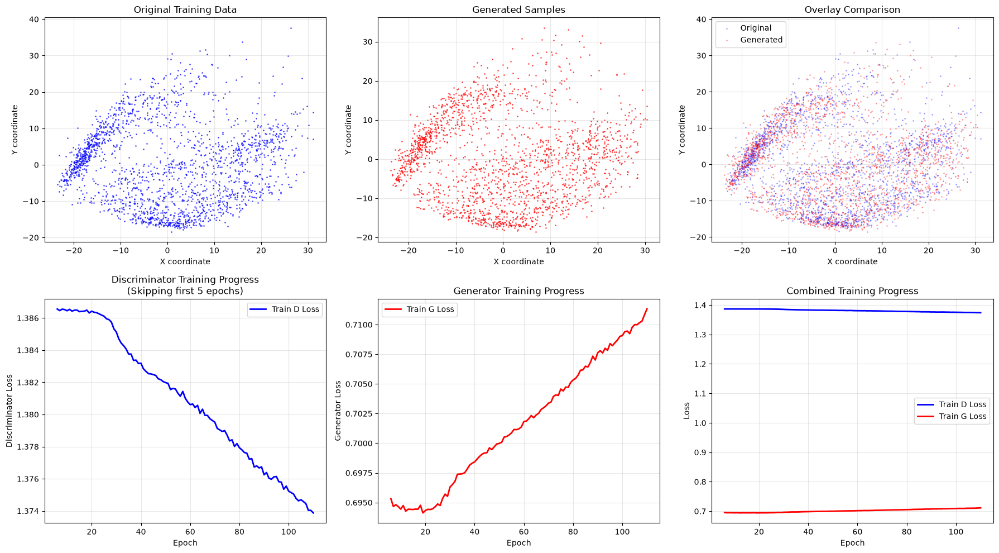

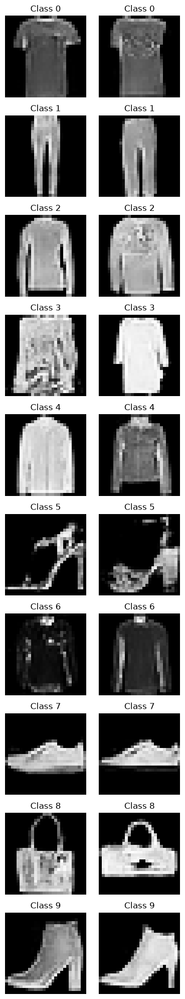

📈 Epoch 110 Summary:
   Train D Loss: 1.3739, Val D Loss: 1.4046
   Train G Loss: 0.7113, Val G Loss: 0.6269

📊 Epoch 111/200
----------------------------------------
Epoch: 111 [0/60000 (0%)]	D_loss: 1.390280	G_loss: 0.708516
Epoch: 111 [6400/60000 (11%)]	D_loss: 1.362890	G_loss: 0.711273
Epoch: 111 [12800/60000 (21%)]	D_loss: 1.373273	G_loss: 0.704684
Epoch: 111 [19200/60000 (32%)]	D_loss: 1.371532	G_loss: 0.719434
Epoch: 111 [25600/60000 (43%)]	D_loss: 1.379107	G_loss: 0.706030
Epoch: 111 [32000/60000 (53%)]	D_loss: 1.368981	G_loss: 0.711323
Epoch: 111 [38400/60000 (64%)]	D_loss: 1.363447	G_loss: 0.709161
Epoch: 111 [44800/60000 (75%)]	D_loss: 1.380233	G_loss: 0.704642
Epoch: 111 [51200/60000 (85%)]	D_loss: 1.381077	G_loss: 0.706345
Epoch: 111 [57600/60000 (96%)]	D_loss: 1.379861	G_loss: 0.701747
====> Epoch: 111 Train D_loss: 1.3733, Train G_loss: 0.7108
====> Epoch: 111 Val D_loss: 1.3806, Val G_loss: 0.7156
📈 Epoch 111 Summary:
   Train D Loss: 1.3733, Val D Loss: 1.3806
   Train

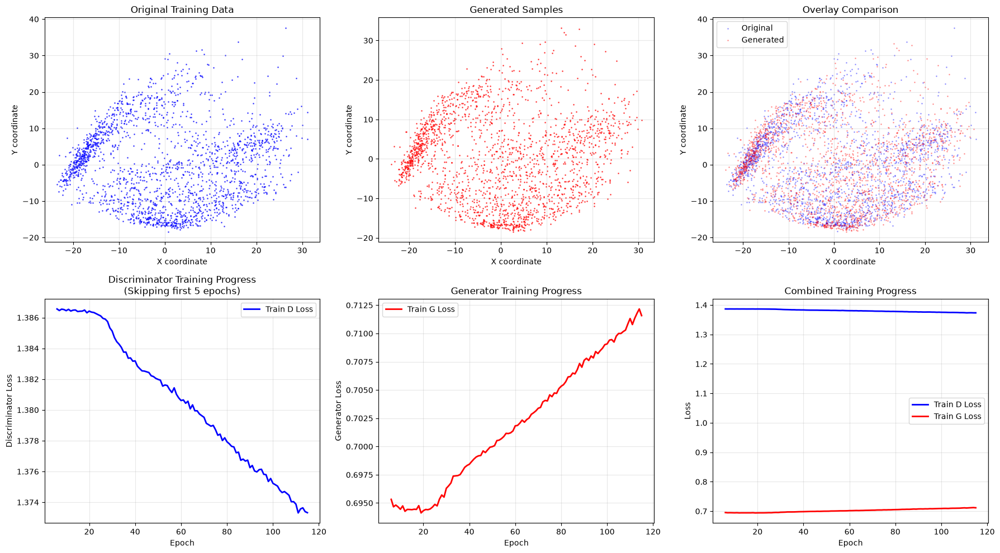

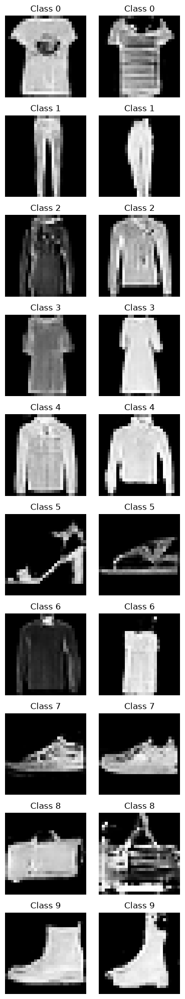

📈 Epoch 115 Summary:
   Train D Loss: 1.3733, Val D Loss: 1.3798
   Train G Loss: 0.7116, Val G Loss: 0.6918

📊 Epoch 116/200
----------------------------------------
Epoch: 116 [0/60000 (0%)]	D_loss: 1.371580	G_loss: 0.701674
Epoch: 116 [6400/60000 (11%)]	D_loss: 1.381976	G_loss: 0.697847
Epoch: 116 [12800/60000 (21%)]	D_loss: 1.377028	G_loss: 0.711291
Epoch: 116 [19200/60000 (32%)]	D_loss: 1.380800	G_loss: 0.726709
Epoch: 116 [25600/60000 (43%)]	D_loss: 1.375454	G_loss: 0.706666
Epoch: 116 [32000/60000 (53%)]	D_loss: 1.381973	G_loss: 0.701493
Epoch: 116 [38400/60000 (64%)]	D_loss: 1.376673	G_loss: 0.700365
Epoch: 116 [44800/60000 (75%)]	D_loss: 1.389957	G_loss: 0.717524
Epoch: 116 [51200/60000 (85%)]	D_loss: 1.371749	G_loss: 0.713531
Epoch: 116 [57600/60000 (96%)]	D_loss: 1.373759	G_loss: 0.707859
====> Epoch: 116 Train D_loss: 1.3727, Train G_loss: 0.7120
====> Epoch: 116 Val D_loss: 1.3797, Val G_loss: 0.6777
📈 Epoch 116 Summary:
   Train D Loss: 1.3727, Val D Loss: 1.3797
   Train

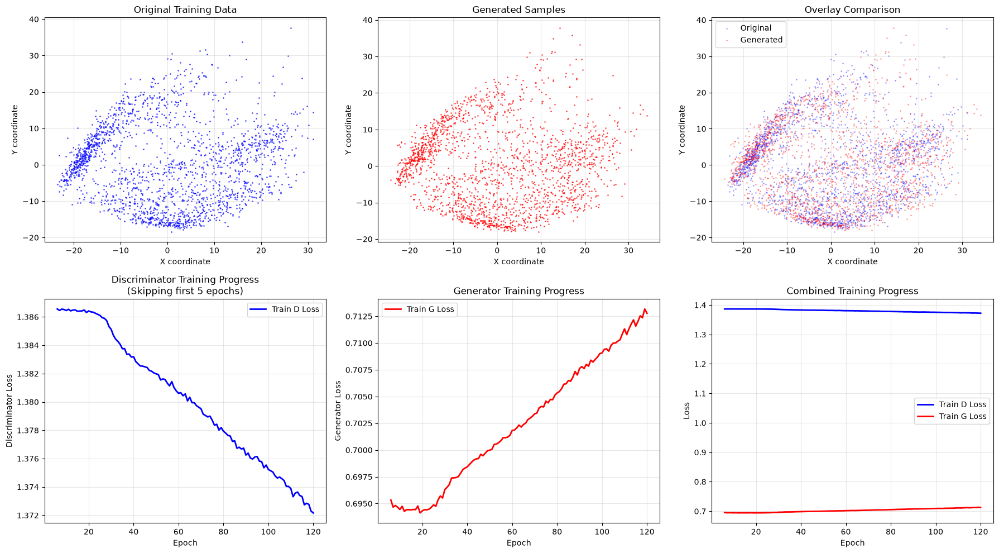

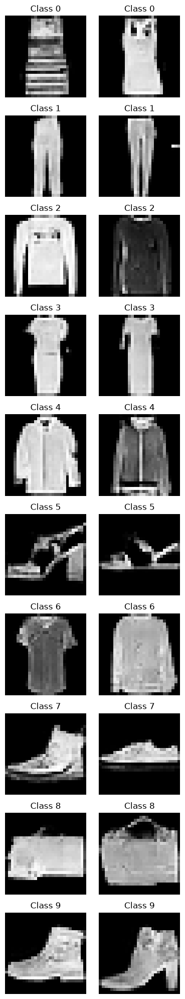

📈 Epoch 120 Summary:
   Train D Loss: 1.3722, Val D Loss: 1.3758
   Train G Loss: 0.7128, Val G Loss: 0.7107

📊 Epoch 121/200
----------------------------------------
Epoch: 121 [0/60000 (0%)]	D_loss: 1.367783	G_loss: 0.703847
Epoch: 121 [6400/60000 (11%)]	D_loss: 1.368407	G_loss: 0.712072
Epoch: 121 [12800/60000 (21%)]	D_loss: 1.369059	G_loss: 0.711840
Epoch: 121 [19200/60000 (32%)]	D_loss: 1.365597	G_loss: 0.715274
Epoch: 121 [25600/60000 (43%)]	D_loss: 1.375977	G_loss: 0.719571
Epoch: 121 [32000/60000 (53%)]	D_loss: 1.364990	G_loss: 0.709724
Epoch: 121 [38400/60000 (64%)]	D_loss: 1.376226	G_loss: 0.717771
Epoch: 121 [44800/60000 (75%)]	D_loss: 1.375239	G_loss: 0.715054
Epoch: 121 [51200/60000 (85%)]	D_loss: 1.366964	G_loss: 0.710040
Epoch: 121 [57600/60000 (96%)]	D_loss: 1.377875	G_loss: 0.704929
====> Epoch: 121 Train D_loss: 1.3721, Train G_loss: 0.7131
====> Epoch: 121 Val D_loss: 1.3745, Val G_loss: 0.6828
📈 Epoch 121 Summary:
   Train D Loss: 1.3721, Val D Loss: 1.3745
   Train

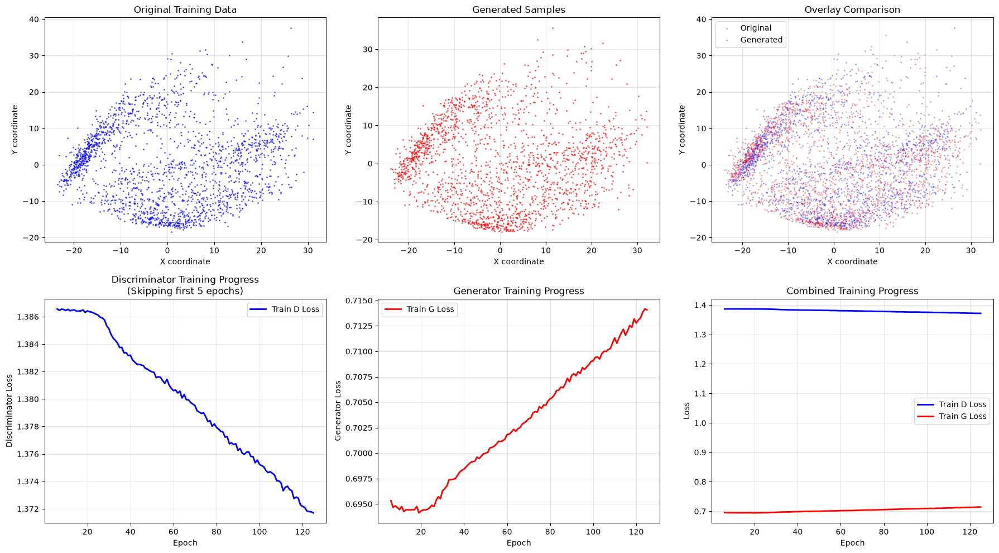

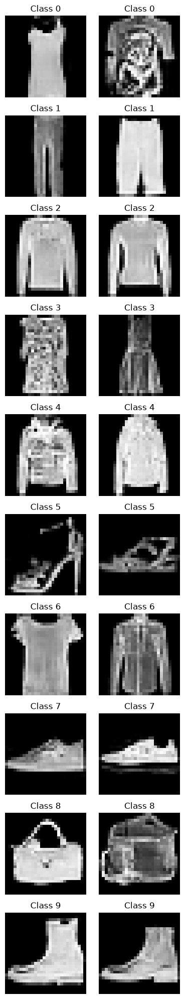

📈 Epoch 125 Summary:
   Train D Loss: 1.3717, Val D Loss: 1.3834
   Train G Loss: 0.7141, Val G Loss: 0.7850

📊 Epoch 126/200
----------------------------------------
Epoch: 126 [0/60000 (0%)]	D_loss: 1.367123	G_loss: 0.699532
Epoch: 126 [6400/60000 (11%)]	D_loss: 1.374304	G_loss: 0.709742
Epoch: 126 [12800/60000 (21%)]	D_loss: 1.362565	G_loss: 0.721307
Epoch: 126 [19200/60000 (32%)]	D_loss: 1.371245	G_loss: 0.718443
Epoch: 126 [25600/60000 (43%)]	D_loss: 1.373636	G_loss: 0.710685
Epoch: 126 [32000/60000 (53%)]	D_loss: 1.373122	G_loss: 0.709762
Epoch: 126 [38400/60000 (64%)]	D_loss: 1.367084	G_loss: 0.706144
Epoch: 126 [44800/60000 (75%)]	D_loss: 1.371591	G_loss: 0.718218
Epoch: 126 [51200/60000 (85%)]	D_loss: 1.369855	G_loss: 0.711250
Epoch: 126 [57600/60000 (96%)]	D_loss: 1.370096	G_loss: 0.717085
====> Epoch: 126 Train D_loss: 1.3713, Train G_loss: 0.7140
====> Epoch: 126 Val D_loss: 1.3835, Val G_loss: 0.7092
📈 Epoch 126 Summary:
   Train D Loss: 1.3713, Val D Loss: 1.3835
   Train

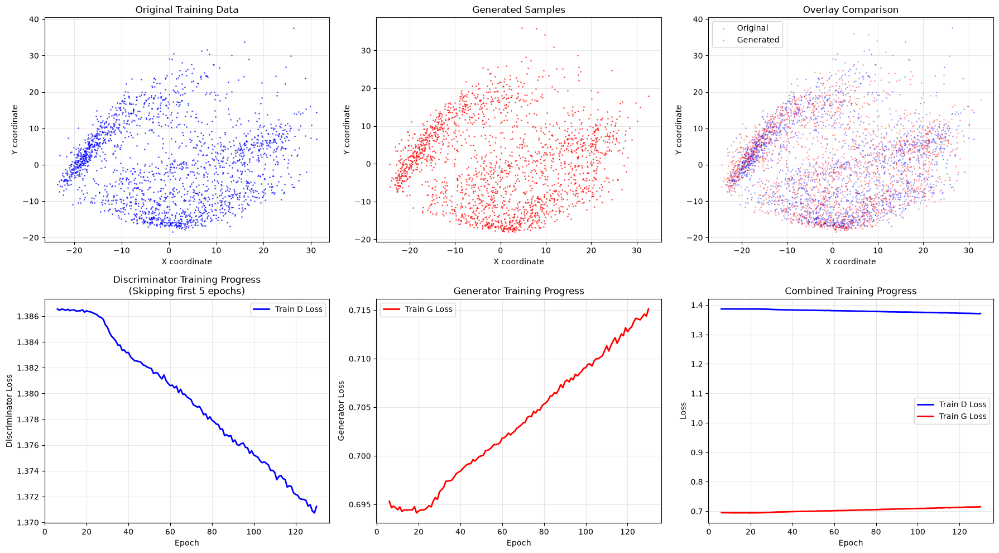

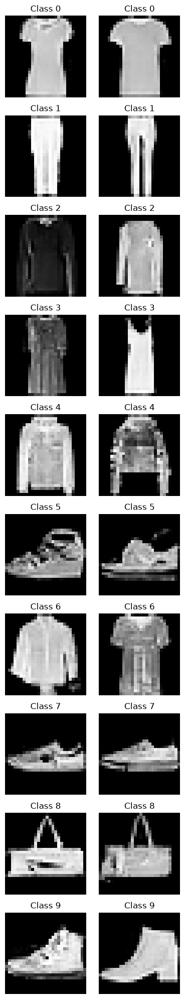

📈 Epoch 130 Summary:
   Train D Loss: 1.3712, Val D Loss: 1.3817
   Train G Loss: 0.7151, Val G Loss: 0.6423

📊 Epoch 131/200
----------------------------------------
Epoch: 131 [0/60000 (0%)]	D_loss: 1.372549	G_loss: 0.708537
Epoch: 131 [6400/60000 (11%)]	D_loss: 1.377310	G_loss: 0.714473
Epoch: 131 [12800/60000 (21%)]	D_loss: 1.382275	G_loss: 0.728013
Epoch: 131 [19200/60000 (32%)]	D_loss: 1.375166	G_loss: 0.708117
Epoch: 131 [25600/60000 (43%)]	D_loss: 1.371008	G_loss: 0.718880
Epoch: 131 [32000/60000 (53%)]	D_loss: 1.370591	G_loss: 0.716160
Epoch: 131 [38400/60000 (64%)]	D_loss: 1.367742	G_loss: 0.708017
Epoch: 131 [44800/60000 (75%)]	D_loss: 1.372951	G_loss: 0.708682
Epoch: 131 [51200/60000 (85%)]	D_loss: 1.372644	G_loss: 0.717494
Epoch: 131 [57600/60000 (96%)]	D_loss: 1.360142	G_loss: 0.711391
====> Epoch: 131 Train D_loss: 1.3704, Train G_loss: 0.7153
====> Epoch: 131 Val D_loss: 1.3786, Val G_loss: 0.7159
📈 Epoch 131 Summary:
   Train D Loss: 1.3704, Val D Loss: 1.3786
   Train

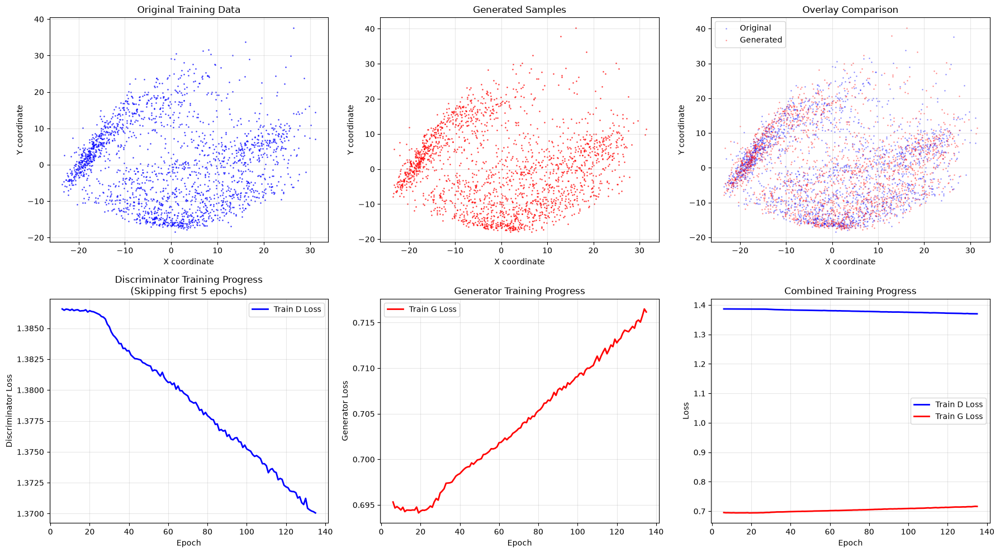

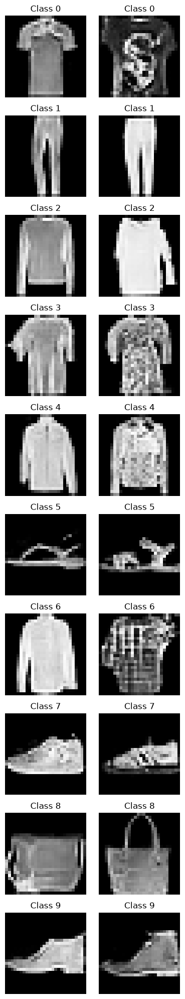

📈 Epoch 135 Summary:
   Train D Loss: 1.3701, Val D Loss: 1.3815
   Train G Loss: 0.7162, Val G Loss: 0.7386

📊 Epoch 136/200
----------------------------------------
Epoch: 136 [0/60000 (0%)]	D_loss: 1.373951	G_loss: 0.725172
Epoch: 136 [6400/60000 (11%)]	D_loss: 1.360466	G_loss: 0.734720
Epoch: 136 [12800/60000 (21%)]	D_loss: 1.372667	G_loss: 0.700342
Epoch: 136 [19200/60000 (32%)]	D_loss: 1.377503	G_loss: 0.725322
Epoch: 136 [25600/60000 (43%)]	D_loss: 1.387489	G_loss: 0.721619
Epoch: 136 [32000/60000 (53%)]	D_loss: 1.364192	G_loss: 0.703649
Epoch: 136 [38400/60000 (64%)]	D_loss: 1.374475	G_loss: 0.712858
Epoch: 136 [44800/60000 (75%)]	D_loss: 1.373033	G_loss: 0.725112
Epoch: 136 [51200/60000 (85%)]	D_loss: 1.368806	G_loss: 0.710877
Epoch: 136 [57600/60000 (96%)]	D_loss: 1.369395	G_loss: 0.713656
====> Epoch: 136 Train D_loss: 1.3702, Train G_loss: 0.7164
====> Epoch: 136 Val D_loss: 1.3793, Val G_loss: 0.7309
📈 Epoch 136 Summary:
   Train D Loss: 1.3702, Val D Loss: 1.3793
   Train

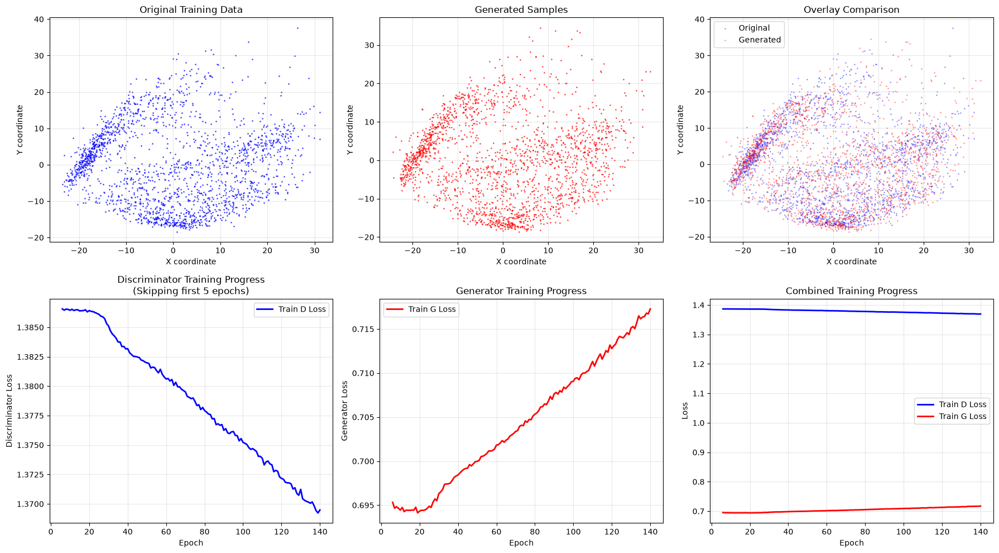

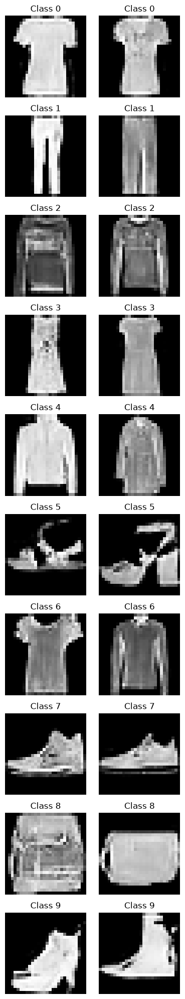

📈 Epoch 140 Summary:
   Train D Loss: 1.3695, Val D Loss: 1.3800
   Train G Loss: 0.7173, Val G Loss: 0.7583

📊 Epoch 141/200
----------------------------------------
Epoch: 141 [0/60000 (0%)]	D_loss: 1.375497	G_loss: 0.710887
Epoch: 141 [6400/60000 (11%)]	D_loss: 1.367903	G_loss: 0.717996
Epoch: 141 [12800/60000 (21%)]	D_loss: 1.361679	G_loss: 0.736576
Epoch: 141 [19200/60000 (32%)]	D_loss: 1.370147	G_loss: 0.717836
Epoch: 141 [25600/60000 (43%)]	D_loss: 1.361678	G_loss: 0.722875
Epoch: 141 [32000/60000 (53%)]	D_loss: 1.372362	G_loss: 0.710741
Epoch: 141 [38400/60000 (64%)]	D_loss: 1.364988	G_loss: 0.712984
Epoch: 141 [44800/60000 (75%)]	D_loss: 1.366914	G_loss: 0.714640
Epoch: 141 [51200/60000 (85%)]	D_loss: 1.375434	G_loss: 0.722783
Epoch: 141 [57600/60000 (96%)]	D_loss: 1.370817	G_loss: 0.715114
====> Epoch: 141 Train D_loss: 1.3694, Train G_loss: 0.7177
====> Epoch: 141 Val D_loss: 1.3872, Val G_loss: 0.7920
📈 Epoch 141 Summary:
   Train D Loss: 1.3694, Val D Loss: 1.3872
   Train

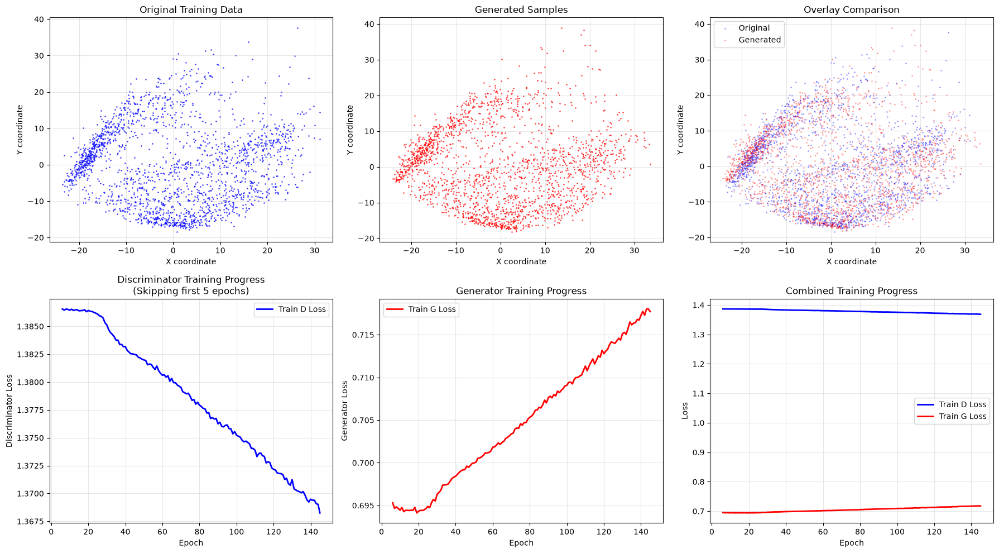

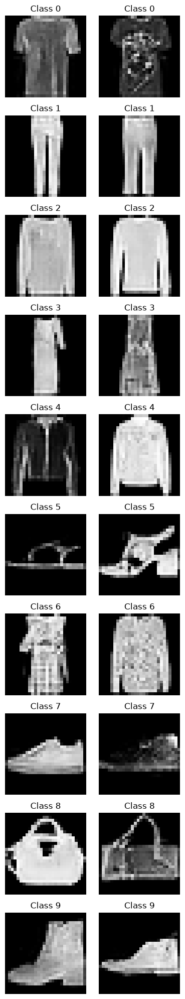

📈 Epoch 145 Summary:
   Train D Loss: 1.3683, Val D Loss: 1.3947
   Train G Loss: 0.7177, Val G Loss: 0.8370

📊 Epoch 146/200
----------------------------------------
Epoch: 146 [0/60000 (0%)]	D_loss: 1.369980	G_loss: 0.722578
Epoch: 146 [6400/60000 (11%)]	D_loss: 1.372347	G_loss: 0.730296
Epoch: 146 [12800/60000 (21%)]	D_loss: 1.373139	G_loss: 0.715807
Epoch: 146 [19200/60000 (32%)]	D_loss: 1.363802	G_loss: 0.735144
Epoch: 146 [25600/60000 (43%)]	D_loss: 1.366925	G_loss: 0.734239
Epoch: 146 [32000/60000 (53%)]	D_loss: 1.365991	G_loss: 0.713732
Epoch: 146 [38400/60000 (64%)]	D_loss: 1.369042	G_loss: 0.733977
Epoch: 146 [44800/60000 (75%)]	D_loss: 1.360718	G_loss: 0.720559
Epoch: 146 [51200/60000 (85%)]	D_loss: 1.368066	G_loss: 0.714185
Epoch: 146 [57600/60000 (96%)]	D_loss: 1.394476	G_loss: 0.713636
====> Epoch: 146 Train D_loss: 1.3689, Train G_loss: 0.7182
====> Epoch: 146 Val D_loss: 1.3889, Val G_loss: 0.6571
📈 Epoch 146 Summary:
   Train D Loss: 1.3689, Val D Loss: 1.3889
   Train

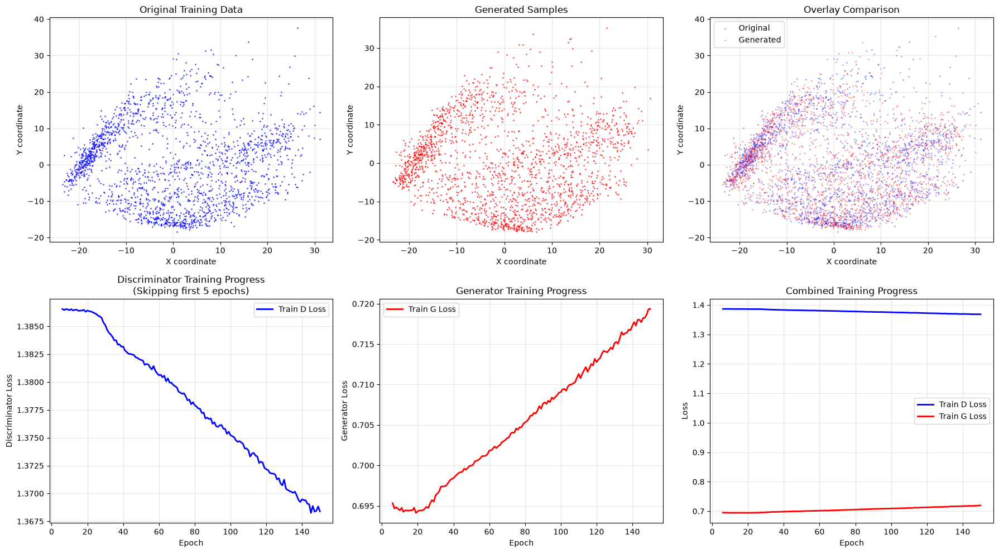

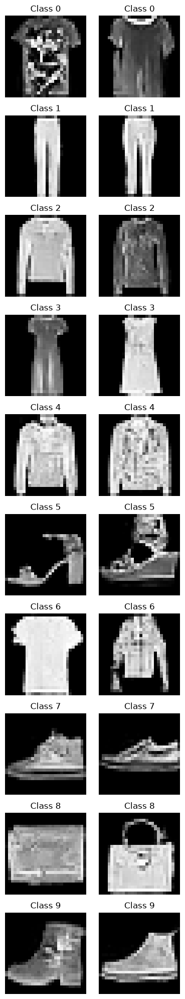

📈 Epoch 150 Summary:
   Train D Loss: 1.3684, Val D Loss: 1.3792
   Train G Loss: 0.7194, Val G Loss: 0.7274

📊 Epoch 151/200
----------------------------------------
Epoch: 151 [0/60000 (0%)]	D_loss: 1.359944	G_loss: 0.710306
Epoch: 151 [6400/60000 (11%)]	D_loss: 1.346182	G_loss: 0.723062
Epoch: 151 [12800/60000 (21%)]	D_loss: 1.348726	G_loss: 0.721093
Epoch: 151 [19200/60000 (32%)]	D_loss: 1.371057	G_loss: 0.714670
Epoch: 151 [25600/60000 (43%)]	D_loss: 1.367547	G_loss: 0.715440
Epoch: 151 [32000/60000 (53%)]	D_loss: 1.352431	G_loss: 0.717945
Epoch: 151 [38400/60000 (64%)]	D_loss: 1.384533	G_loss: 0.693537
Epoch: 151 [44800/60000 (75%)]	D_loss: 1.370018	G_loss: 0.720186
Epoch: 151 [51200/60000 (85%)]	D_loss: 1.364410	G_loss: 0.724706
Epoch: 151 [57600/60000 (96%)]	D_loss: 1.364226	G_loss: 0.711728
====> Epoch: 151 Train D_loss: 1.3679, Train G_loss: 0.7191
====> Epoch: 151 Val D_loss: 1.3799, Val G_loss: 0.7111
📈 Epoch 151 Summary:
   Train D Loss: 1.3679, Val D Loss: 1.3799
   Train

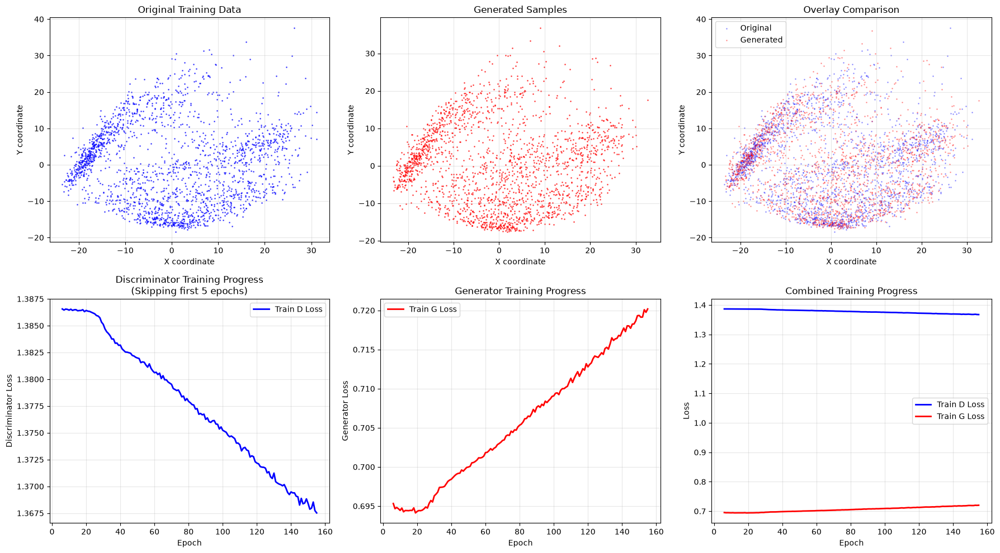

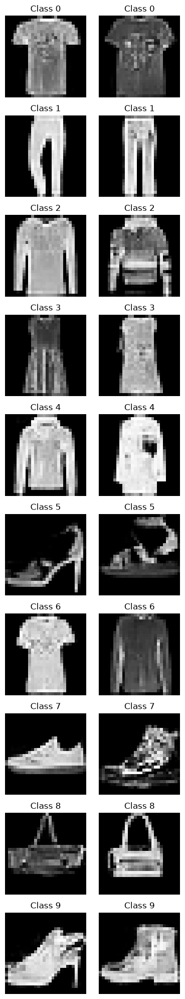

📈 Epoch 155 Summary:
   Train D Loss: 1.3675, Val D Loss: 1.3867
   Train G Loss: 0.7202, Val G Loss: 0.7408

📊 Epoch 156/200
----------------------------------------
Epoch: 156 [0/60000 (0%)]	D_loss: 1.370031	G_loss: 0.719543
Epoch: 156 [6400/60000 (11%)]	D_loss: 1.365867	G_loss: 0.712665
Epoch: 156 [12800/60000 (21%)]	D_loss: 1.348086	G_loss: 0.724586
Epoch: 156 [19200/60000 (32%)]	D_loss: 1.374895	G_loss: 0.718658
Epoch: 156 [25600/60000 (43%)]	D_loss: 1.373161	G_loss: 0.718188
Epoch: 156 [32000/60000 (53%)]	D_loss: 1.370197	G_loss: 0.714933
Epoch: 156 [38400/60000 (64%)]	D_loss: 1.365736	G_loss: 0.738507
Epoch: 156 [44800/60000 (75%)]	D_loss: 1.377879	G_loss: 0.706361
Epoch: 156 [51200/60000 (85%)]	D_loss: 1.379539	G_loss: 0.722621
Epoch: 156 [57600/60000 (96%)]	D_loss: 1.351995	G_loss: 0.738002
====> Epoch: 156 Train D_loss: 1.3673, Train G_loss: 0.7202
====> Epoch: 156 Val D_loss: 1.3844, Val G_loss: 0.7670
📈 Epoch 156 Summary:
   Train D Loss: 1.3673, Val D Loss: 1.3844
   Train

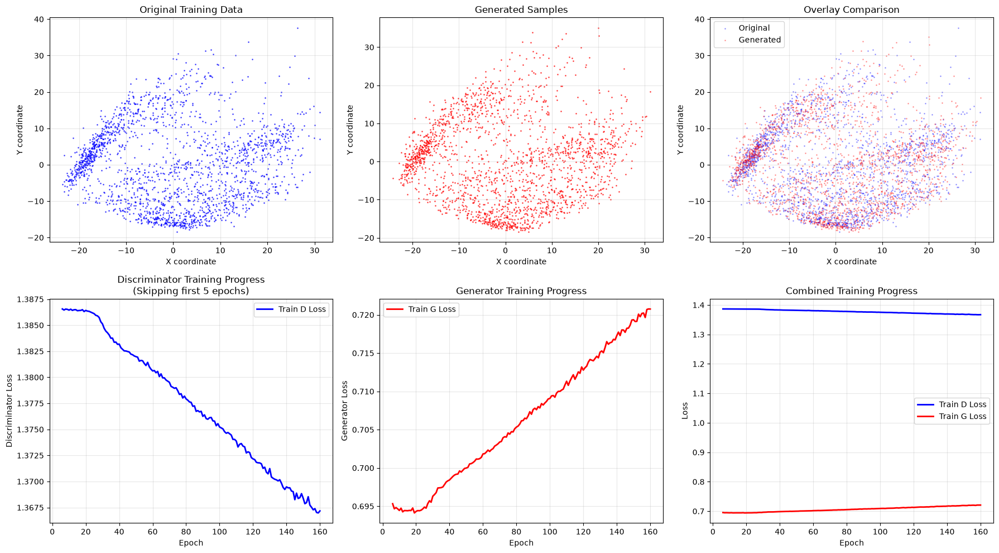

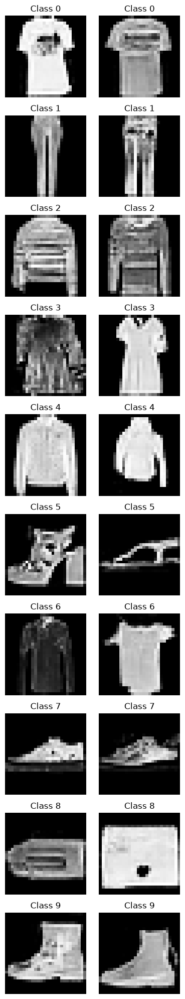

📈 Epoch 160 Summary:
   Train D Loss: 1.3672, Val D Loss: 1.3803
   Train G Loss: 0.7208, Val G Loss: 0.7680

📊 Epoch 161/200
----------------------------------------
Epoch: 161 [0/60000 (0%)]	D_loss: 1.372064	G_loss: 0.723081
Epoch: 161 [6400/60000 (11%)]	D_loss: 1.371564	G_loss: 0.728614
Epoch: 161 [12800/60000 (21%)]	D_loss: 1.366865	G_loss: 0.724535
Epoch: 161 [19200/60000 (32%)]	D_loss: 1.359148	G_loss: 0.718875
Epoch: 161 [25600/60000 (43%)]	D_loss: 1.384454	G_loss: 0.712272
Epoch: 161 [32000/60000 (53%)]	D_loss: 1.369851	G_loss: 0.730551
Epoch: 161 [38400/60000 (64%)]	D_loss: 1.347728	G_loss: 0.736547
Epoch: 161 [44800/60000 (75%)]	D_loss: 1.363167	G_loss: 0.736648
Epoch: 161 [51200/60000 (85%)]	D_loss: 1.349877	G_loss: 0.713913
Epoch: 161 [57600/60000 (96%)]	D_loss: 1.365510	G_loss: 0.707714
====> Epoch: 161 Train D_loss: 1.3670, Train G_loss: 0.7210
====> Epoch: 161 Val D_loss: 1.3879, Val G_loss: 0.6644
📈 Epoch 161 Summary:
   Train D Loss: 1.3670, Val D Loss: 1.3879
   Train

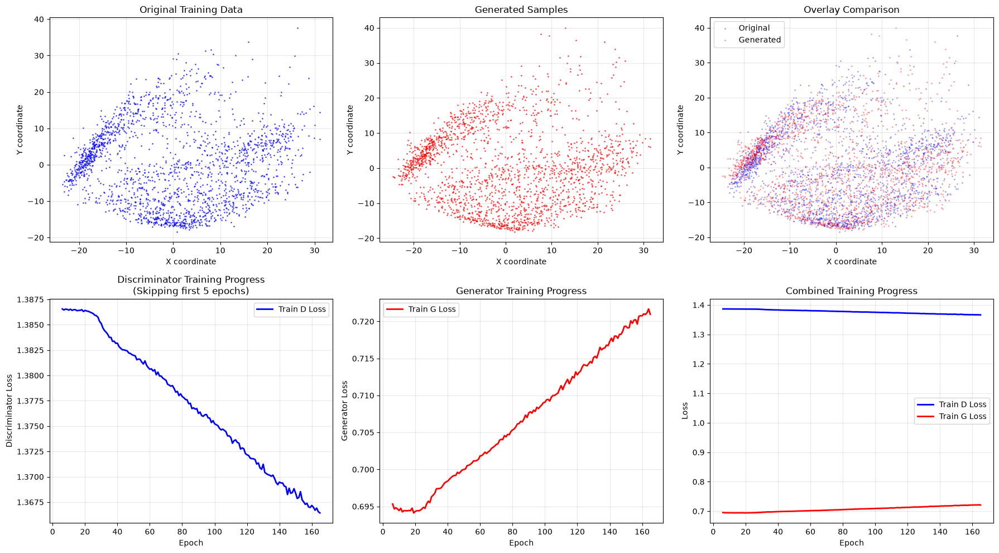

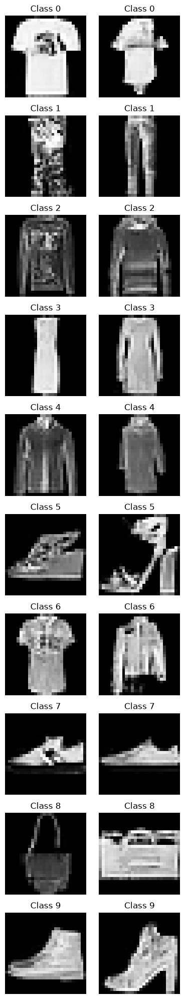

📈 Epoch 165 Summary:
   Train D Loss: 1.3664, Val D Loss: 1.3746
   Train G Loss: 0.7210, Val G Loss: 0.7177

📊 Epoch 166/200
----------------------------------------
Epoch: 166 [0/60000 (0%)]	D_loss: 1.364893	G_loss: 0.715881
Epoch: 166 [6400/60000 (11%)]	D_loss: 1.372622	G_loss: 0.720662
Epoch: 166 [12800/60000 (21%)]	D_loss: 1.361947	G_loss: 0.725335
Epoch: 166 [19200/60000 (32%)]	D_loss: 1.368403	G_loss: 0.719132
Epoch: 166 [25600/60000 (43%)]	D_loss: 1.363894	G_loss: 0.723760
Epoch: 166 [32000/60000 (53%)]	D_loss: 1.389929	G_loss: 0.712646
Epoch: 166 [38400/60000 (64%)]	D_loss: 1.361312	G_loss: 0.716331
Epoch: 166 [44800/60000 (75%)]	D_loss: 1.378609	G_loss: 0.740167
Epoch: 166 [51200/60000 (85%)]	D_loss: 1.361391	G_loss: 0.719051
Epoch: 166 [57600/60000 (96%)]	D_loss: 1.379412	G_loss: 0.733279
====> Epoch: 166 Train D_loss: 1.3665, Train G_loss: 0.7221
====> Epoch: 166 Val D_loss: 1.3834, Val G_loss: 0.6708
📈 Epoch 166 Summary:
   Train D Loss: 1.3665, Val D Loss: 1.3834
   Train

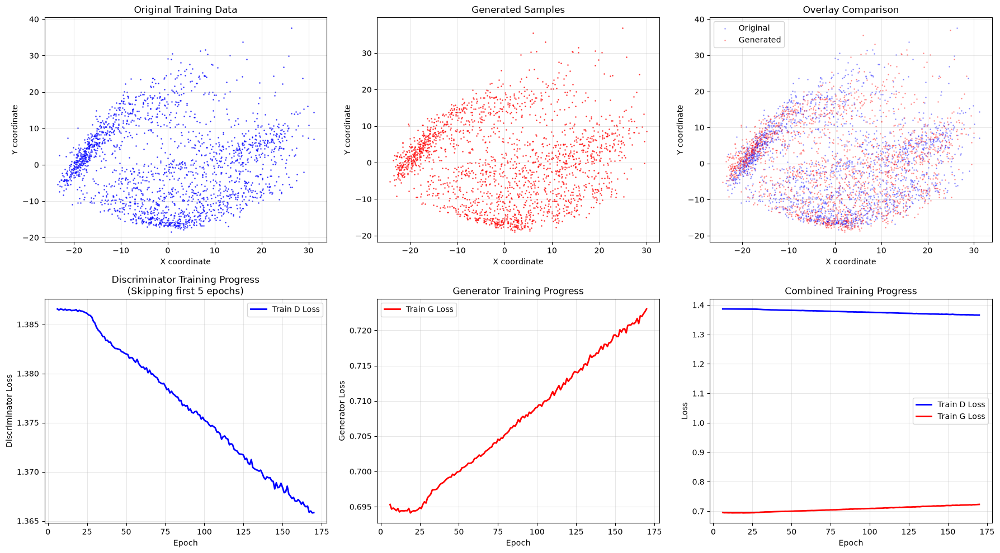

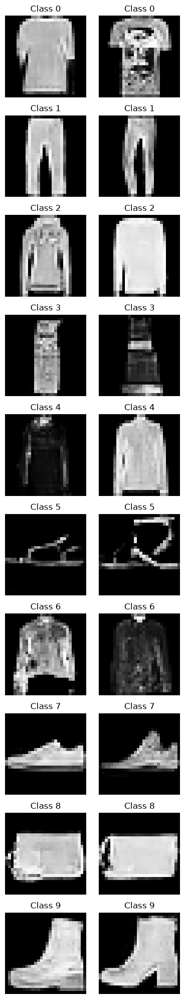

📈 Epoch 170 Summary:
   Train D Loss: 1.3658, Val D Loss: 1.3860
   Train G Loss: 0.7230, Val G Loss: 0.6670

📊 Epoch 171/200
----------------------------------------
Epoch: 171 [0/60000 (0%)]	D_loss: 1.362023	G_loss: 0.717768
Epoch: 171 [6400/60000 (11%)]	D_loss: 1.373787	G_loss: 0.725092
Epoch: 171 [12800/60000 (21%)]	D_loss: 1.359468	G_loss: 0.711518
Epoch: 171 [19200/60000 (32%)]	D_loss: 1.371846	G_loss: 0.715583
Epoch: 171 [25600/60000 (43%)]	D_loss: 1.350461	G_loss: 0.710720
Epoch: 171 [32000/60000 (53%)]	D_loss: 1.370772	G_loss: 0.721281
Epoch: 171 [38400/60000 (64%)]	D_loss: 1.369911	G_loss: 0.717674
Epoch: 171 [44800/60000 (75%)]	D_loss: 1.374393	G_loss: 0.712169
Epoch: 171 [51200/60000 (85%)]	D_loss: 1.357994	G_loss: 0.717014
Epoch: 171 [57600/60000 (96%)]	D_loss: 1.370046	G_loss: 0.729263
====> Epoch: 171 Train D_loss: 1.3653, Train G_loss: 0.7228
====> Epoch: 171 Val D_loss: 1.3869, Val G_loss: 0.8076
📈 Epoch 171 Summary:
   Train D Loss: 1.3653, Val D Loss: 1.3869
   Train

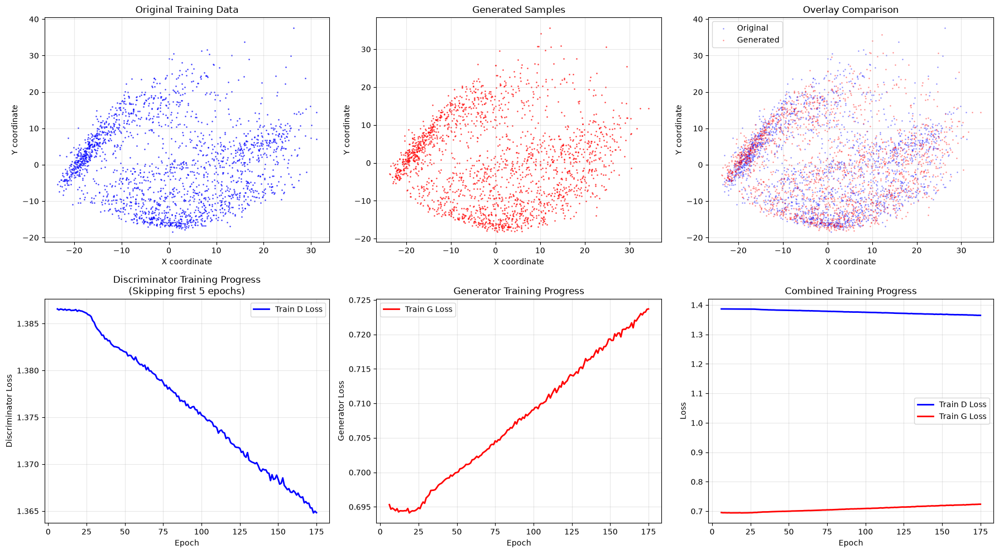

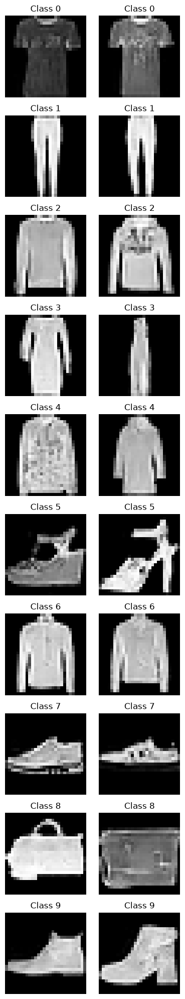

📈 Epoch 175 Summary:
   Train D Loss: 1.3648, Val D Loss: 1.3819
   Train G Loss: 0.7237, Val G Loss: 0.6629

📊 Epoch 176/200
----------------------------------------
Epoch: 176 [0/60000 (0%)]	D_loss: 1.353956	G_loss: 0.731273
Epoch: 176 [6400/60000 (11%)]	D_loss: 1.358280	G_loss: 0.728247
Epoch: 176 [12800/60000 (21%)]	D_loss: 1.353296	G_loss: 0.738369
Epoch: 176 [19200/60000 (32%)]	D_loss: 1.366919	G_loss: 0.721115
Epoch: 176 [25600/60000 (43%)]	D_loss: 1.373612	G_loss: 0.719555
Epoch: 176 [32000/60000 (53%)]	D_loss: 1.372854	G_loss: 0.746026
Epoch: 176 [38400/60000 (64%)]	D_loss: 1.366028	G_loss: 0.721784
Epoch: 176 [44800/60000 (75%)]	D_loss: 1.367075	G_loss: 0.716550
Epoch: 176 [51200/60000 (85%)]	D_loss: 1.385082	G_loss: 0.713228
Epoch: 176 [57600/60000 (96%)]	D_loss: 1.353255	G_loss: 0.745479
====> Epoch: 176 Train D_loss: 1.3649, Train G_loss: 0.7235
====> Epoch: 176 Val D_loss: 1.3789, Val G_loss: 0.6939
📈 Epoch 176 Summary:
   Train D Loss: 1.3649, Val D Loss: 1.3789
   Train

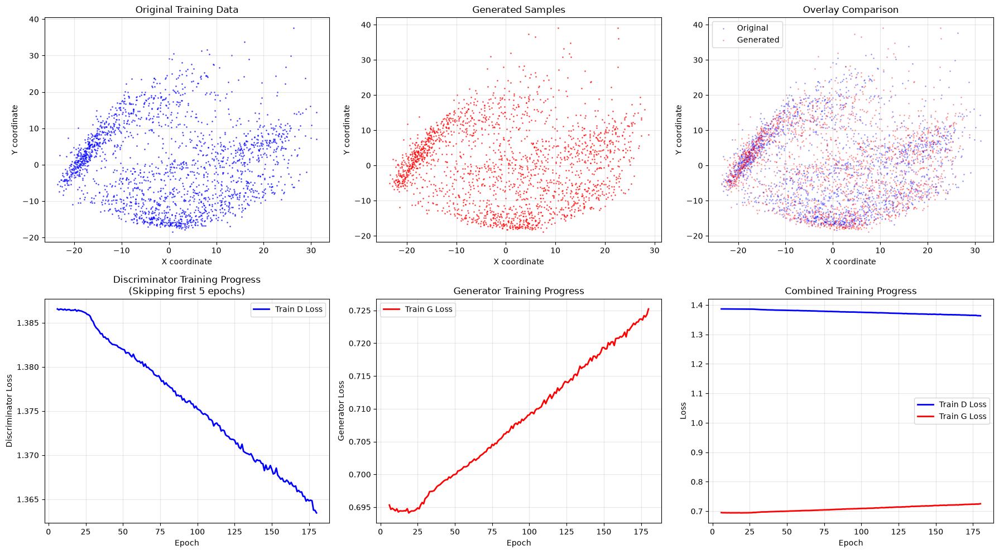

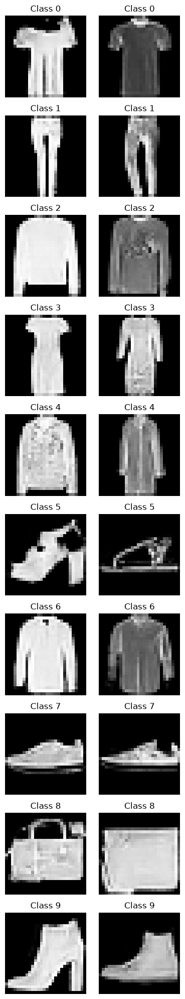

📈 Epoch 180 Summary:
   Train D Loss: 1.3635, Val D Loss: 1.3998
   Train G Loss: 0.7252, Val G Loss: 0.8261

📊 Epoch 181/200
----------------------------------------
Epoch: 181 [0/60000 (0%)]	D_loss: 1.362075	G_loss: 0.735444
Epoch: 181 [6400/60000 (11%)]	D_loss: 1.346012	G_loss: 0.747209
Epoch: 181 [12800/60000 (21%)]	D_loss: 1.358541	G_loss: 0.707571
Epoch: 181 [19200/60000 (32%)]	D_loss: 1.372708	G_loss: 0.714939
Epoch: 181 [25600/60000 (43%)]	D_loss: 1.370142	G_loss: 0.724669
Epoch: 181 [32000/60000 (53%)]	D_loss: 1.365611	G_loss: 0.719210
Epoch: 181 [38400/60000 (64%)]	D_loss: 1.358743	G_loss: 0.759702
Epoch: 181 [44800/60000 (75%)]	D_loss: 1.363795	G_loss: 0.735552
Epoch: 181 [51200/60000 (85%)]	D_loss: 1.374061	G_loss: 0.726056
Epoch: 181 [57600/60000 (96%)]	D_loss: 1.384897	G_loss: 0.737441
====> Epoch: 181 Train D_loss: 1.3637, Train G_loss: 0.7251
====> Epoch: 181 Val D_loss: 1.3801, Val G_loss: 0.7533
📈 Epoch 181 Summary:
   Train D Loss: 1.3637, Val D Loss: 1.3801
   Train

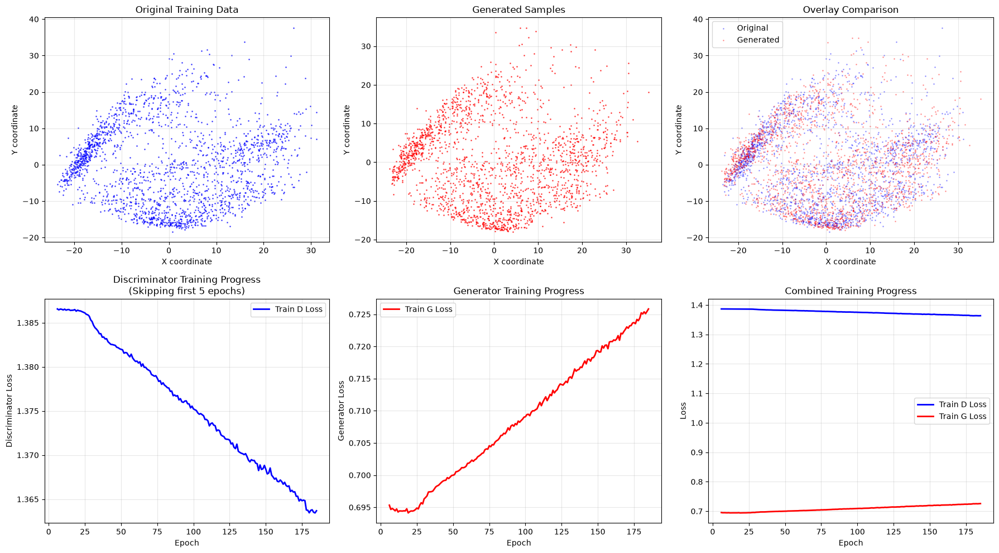

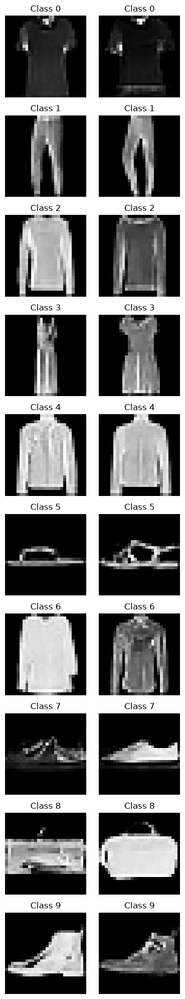

📈 Epoch 185 Summary:
   Train D Loss: 1.3637, Val D Loss: 1.3819
   Train G Loss: 0.7258, Val G Loss: 0.7565

📊 Epoch 186/200
----------------------------------------
Epoch: 186 [0/60000 (0%)]	D_loss: 1.366636	G_loss: 0.716459
Epoch: 186 [6400/60000 (11%)]	D_loss: 1.357807	G_loss: 0.737781
Epoch: 186 [12800/60000 (21%)]	D_loss: 1.364248	G_loss: 0.721635
Epoch: 186 [19200/60000 (32%)]	D_loss: 1.353610	G_loss: 0.728933
Epoch: 186 [25600/60000 (43%)]	D_loss: 1.361871	G_loss: 0.721254
Epoch: 186 [32000/60000 (53%)]	D_loss: 1.368605	G_loss: 0.719318
Epoch: 186 [38400/60000 (64%)]	D_loss: 1.362677	G_loss: 0.716105
Epoch: 186 [44800/60000 (75%)]	D_loss: 1.339931	G_loss: 0.729878
Epoch: 186 [51200/60000 (85%)]	D_loss: 1.356075	G_loss: 0.719612
Epoch: 186 [57600/60000 (96%)]	D_loss: 1.375332	G_loss: 0.719204
====> Epoch: 186 Train D_loss: 1.3635, Train G_loss: 0.7259
====> Epoch: 186 Val D_loss: 1.3904, Val G_loss: 0.8017
📈 Epoch 186 Summary:
   Train D Loss: 1.3635, Val D Loss: 1.3904
   Train

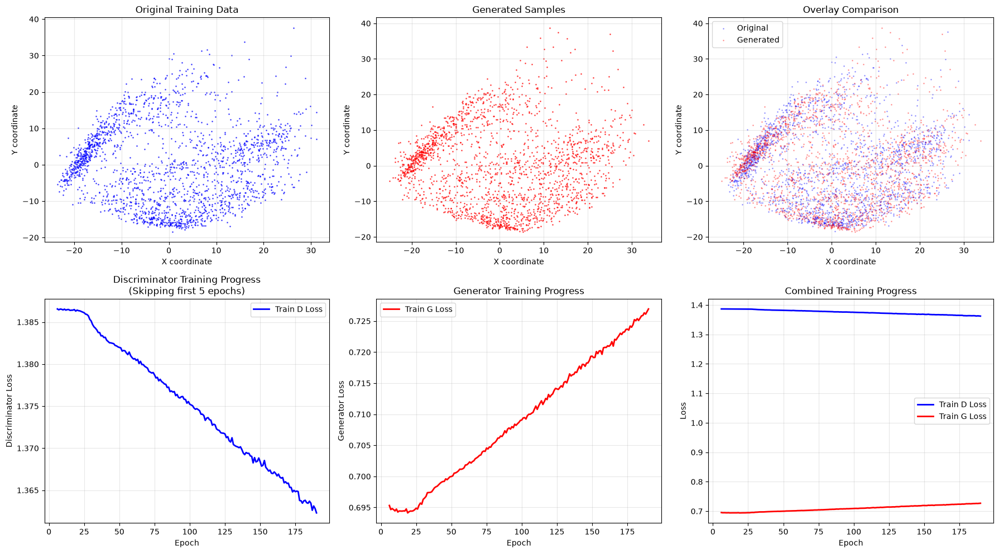

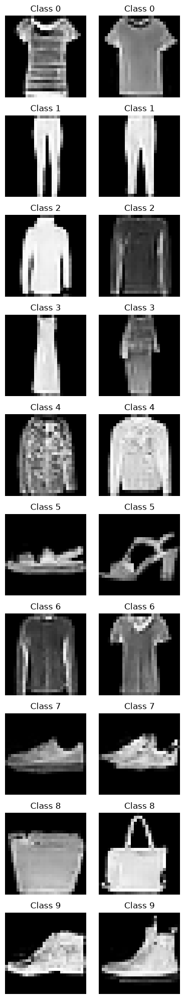

📈 Epoch 190 Summary:
   Train D Loss: 1.3623, Val D Loss: 1.3771
   Train G Loss: 0.7269, Val G Loss: 0.6848

📊 Epoch 191/200
----------------------------------------
Epoch: 191 [0/60000 (0%)]	D_loss: 1.375052	G_loss: 0.716958
Epoch: 191 [6400/60000 (11%)]	D_loss: 1.372790	G_loss: 0.727924
Epoch: 191 [12800/60000 (21%)]	D_loss: 1.355549	G_loss: 0.713550
Epoch: 191 [19200/60000 (32%)]	D_loss: 1.360587	G_loss: 0.741653
Epoch: 191 [25600/60000 (43%)]	D_loss: 1.357909	G_loss: 0.729067
Epoch: 191 [32000/60000 (53%)]	D_loss: 1.375651	G_loss: 0.731774
Epoch: 191 [38400/60000 (64%)]	D_loss: 1.362259	G_loss: 0.727123
Epoch: 191 [44800/60000 (75%)]	D_loss: 1.363155	G_loss: 0.727137
Epoch: 191 [51200/60000 (85%)]	D_loss: 1.370720	G_loss: 0.725090
Epoch: 191 [57600/60000 (96%)]	D_loss: 1.350630	G_loss: 0.743841
====> Epoch: 191 Train D_loss: 1.3632, Train G_loss: 0.7273
====> Epoch: 191 Val D_loss: 1.3811, Val G_loss: 0.7138
📈 Epoch 191 Summary:
   Train D Loss: 1.3632, Val D Loss: 1.3811
   Train

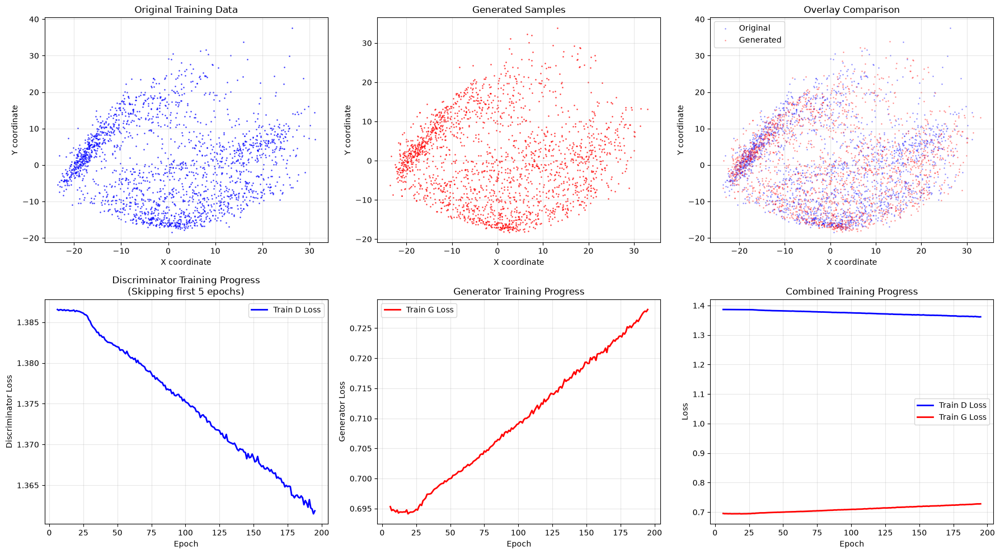

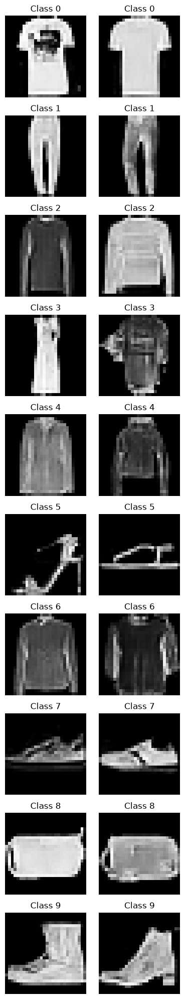

📈 Epoch 195 Summary:
   Train D Loss: 1.3619, Val D Loss: 1.3743
   Train G Loss: 0.7281, Val G Loss: 0.7228

📊 Epoch 196/200
----------------------------------------
Epoch: 196 [0/60000 (0%)]	D_loss: 1.349934	G_loss: 0.718956
Epoch: 196 [6400/60000 (11%)]	D_loss: 1.366909	G_loss: 0.719465
Epoch: 196 [12800/60000 (21%)]	D_loss: 1.364440	G_loss: 0.718694
Epoch: 196 [19200/60000 (32%)]	D_loss: 1.374447	G_loss: 0.732314
Epoch: 196 [25600/60000 (43%)]	D_loss: 1.360293	G_loss: 0.711656
Epoch: 196 [32000/60000 (53%)]	D_loss: 1.355032	G_loss: 0.719339
Epoch: 196 [38400/60000 (64%)]	D_loss: 1.368722	G_loss: 0.730555
Epoch: 196 [44800/60000 (75%)]	D_loss: 1.354127	G_loss: 0.738941
Epoch: 196 [51200/60000 (85%)]	D_loss: 1.359533	G_loss: 0.723993
Epoch: 196 [57600/60000 (96%)]	D_loss: 1.376670	G_loss: 0.715615
====> Epoch: 196 Train D_loss: 1.3620, Train G_loss: 0.7282
====> Epoch: 196 Val D_loss: 1.3811, Val G_loss: 0.7753
📈 Epoch 196 Summary:
   Train D Loss: 1.3620, Val D Loss: 1.3811
   Train

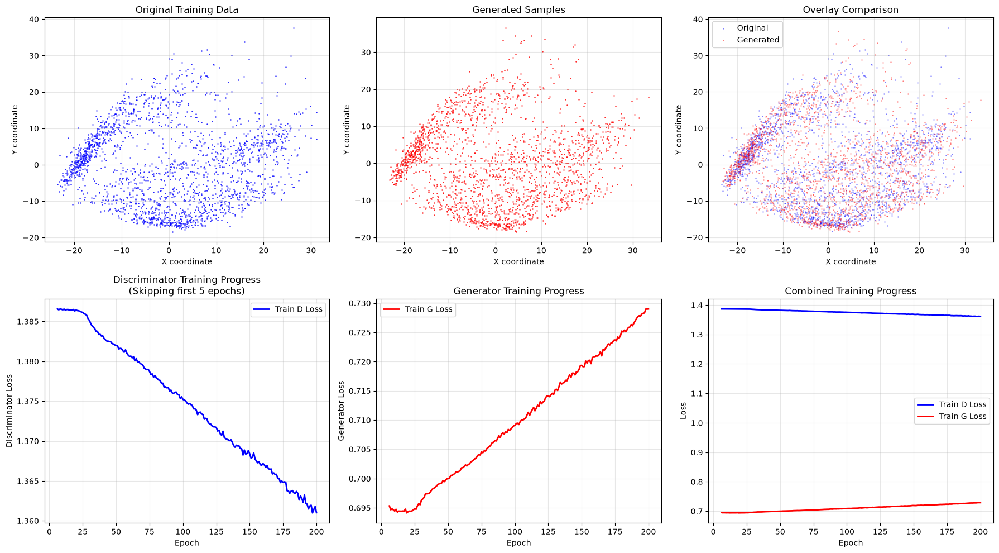

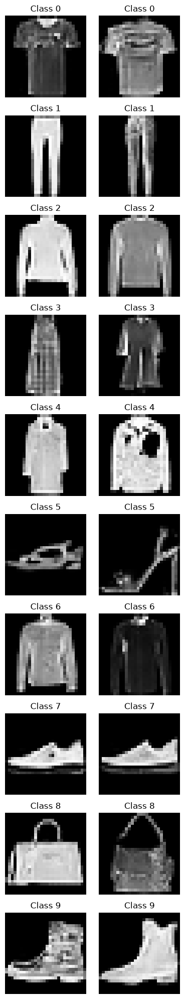

📈 Epoch 200 Summary:
   Train D Loss: 1.3610, Val D Loss: 1.3797
   Train G Loss: 0.7290, Val G Loss: 0.7393

🎉 Training completed!

🎨 Final comprehensive visualization:


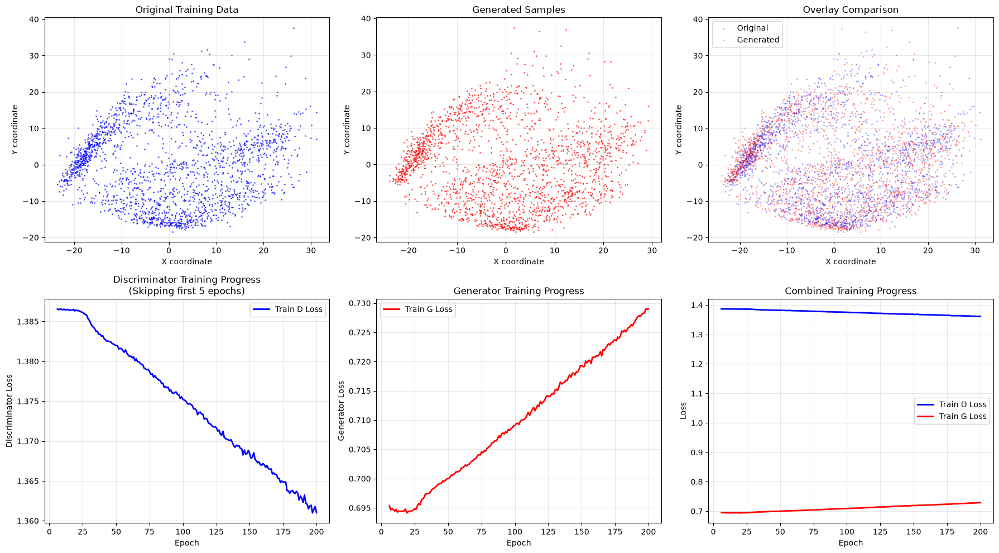

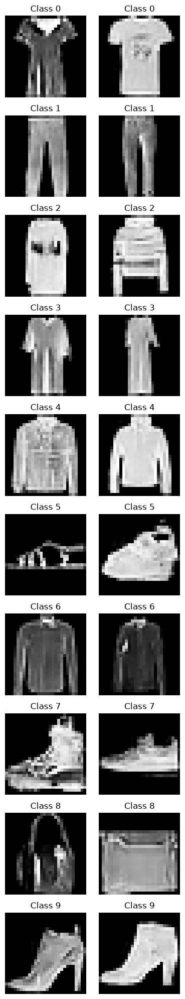

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


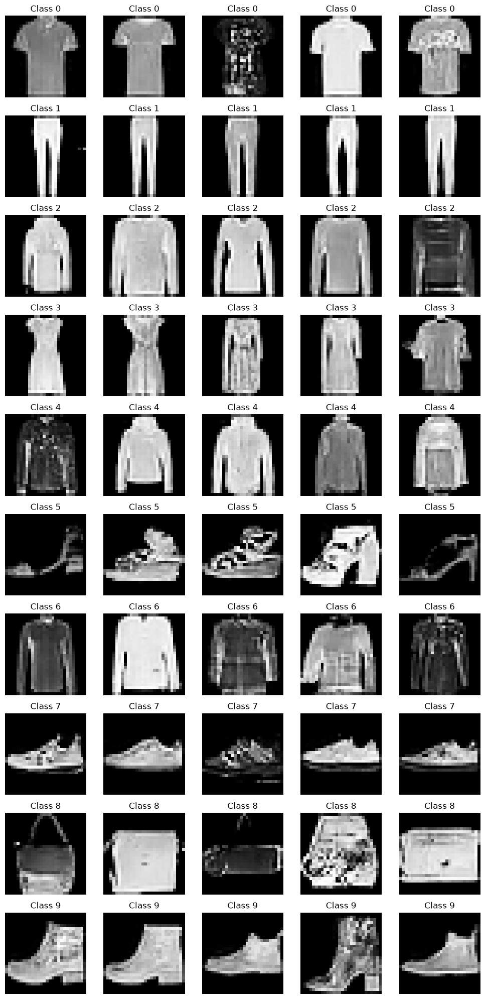

Real data confidence with matching classes: 0.502
Fake data confidence with requested classes: 0.481


In [15]:
TARGET_CLASSES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
SAMPLES_PER_CLASS = 5

visualize_class_samples(TARGET_CLASSES, samples_per_class=SAMPLES_PER_CLASS)

generated_sevens = generate_samples(20, classes=7)
generated_digits = generate_samples(len(TARGET_CLASSES), classes=TARGET_CLASSES)

generator.eval()
discriminator.eval()
with torch.no_grad():
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_classes = train_data.targets[:100].to(device)
    real_pred = discriminator(real_batch, real_classes).mean().item()

    fake_classes = torch.tensor(TARGET_CLASSES, device=device).repeat(100)[:100]
    noise = torch.randn(100, NOISE_DIM, device=device)
    fake_batch = generator(noise, fake_classes)
    fake_pred = discriminator(fake_batch, fake_classes).mean().item()

print(f'Real data confidence with matching classes: {real_pred:.3f}')
print(f'Fake data confidence with requested classes: {fake_pred:.3f}')
